# Myocardial infarction: finite-iteration logistic fits

**Preferred model:** no intercept, centered/whitened predictors, logistic posterior
likelihood, and no explicit fitting penalty. The auxiliary fit is either exact
weighted least squares or finite-iteration weighted logistic FISTA. Each logistic
fit starts at zero, uses weighted mean loss, a maximum step equal to the reciprocal
of the global weighted logistic curvature bound, and monotone FISTA/backtracking.
Budgets are **1, 3, 10, 30, 100, 300, 1,000** iterations. Actual iteration counts,
gradient residuals, and coefficient norms are recorded; failure to converge is
intentional in this early-stopping study, not silently treated as an exact optimum.

The 1,692 age-sorted observations have 110 mean-imputed, centered predictors,
whitened using covariance plus $10^{-6}I$ and divided by $\sqrt n$.
Minimum segment size is $\Delta\in\{1,85,169\}$. At each setting, the count prior
assigns probability $1/2$ to zero and one change; conditional location is uniform
over admissible distinct-age splits. There is one null configuration (all signal 0).
No fitted intercept, prevalence offset, or likelihood temperature is introduced.

Signal-strength estimation starts at $I_2$, uses damping 0.25 and eigenvalue bounds
$[10^{-4},100]$, and saves **1, 3, 10, 30** updates; the direct approximate LS moment
fit is also included. Logistic auxiliary and posterior budgets are fully crossed,
with matched-budget results identified separately. The baseline contains **693**
posterior comparisons (3 minimum segment sizes × 33 rho settings × 7 posterior fits).

Primary states use 256 Sobol draws (seed 42), at most 60 state-solver evaluations,
and 160-node Gaussian quadrature for reported likelihoods. In each auxiliary class,
the three closest reference curves and two highest-count-probability curves within
0.15 TV of that class's best are selected for checks using 512 draws/seed 42 and
1,024 draws/seed 123, both with at most 100 solver evaluations. **There is no
$P(1)>0.5$ eligibility threshold.** TV is computed on the full reference age grid,
including reference probability excluded by a larger $\Delta$.

This is a **post-hoc heuristic sensitivity exploration**. The existing asymptotic
state equations are used as an approximation for early-stopped fits; they do not
become exact finite-iteration theory. Independent numerical draws assess integration
sensitivity, not independent-data validity. Nonzero moment residuals are retained.
The zero-offset Gaussian logistic model implies marginal prevalence 1/2, versus
about 0.232 observed; centering does not fix that mismatch. Similarity to the old
curve is an explicit exploratory objective, not evidence of statistical correctness.


In [1]:
"""Finite-iteration heuristic sensitivity; all settings and diagnostics retained."""
from tools.myocardial_exploration import *
from tools.myocardial_exploration_refinement import evaluate_refined
from WERM.myocardial_early_stopping import early_logistic_fit
from WERM.myocardial_numerics import logistic_prox_fast

FIT_BUDGETS = (1, 3, 10, 30, 100, 300, 1000)
SOURCE = Path('results/myocardial_exploration_4026d0e775d2')


def reference_distribution():
    import jax
    jax.config.update('jax_enable_x64', True)
    ref = pickle.load(open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl','rb'))
    _, _, ages, locations = load_data()
    a=np.asarray(ref['unique_ages']).ravel();p=np.asarray(ref['posterior']).ravel()
    keep=np.isin(a,ages[locations]);a,p=a[keep],p[keep];p=p/p.sum()
    return dict(zip(a,p))


def finite_fit(X,y,phi,budget):
    fits=[early_logistic_fit(X,y,w,budget) for w in phi]
    B=np.column_stack([f.coef for f in fits]);theta=X@B
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    if not np.isfinite(V).all():raise FloatingPointError('Nonfinite adjusted fit')
    return dict(theta=theta,V=V,b=b,coef=B,penalty='none',strength=0.,budget=budget,
        checks=[dict(kkt=f.kkt_violation,iterations=f.n_iter,success=f.converged,
                     objective=f.objective,norm=float(np.linalg.norm(f.coef))) for f in fits])


def auxiliary_task(delta,budget,X,y,root):
    path=root/f'aux_d{delta}_early{budget}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    setting=pickle.load((SOURCE/f'fits_delta{delta}.pkl').open('rb'))
    fit=finite_fit(X,y,setting['phi'],budget)
    pilot_eta,psi=pilot(fit['theta'],y,setting['eta'],'logistic')
    S=fit['V'].T@fit['V']/len(y)
    import WERM.myocardial_approximate as implementation
    old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
    try:
        scenarios=[dict(r,auxiliary=f'early{budget}',pilot=pilot_eta,loss='logistic',
                        auxiliary_budget=budget) for r in rho_path(S,setting['phi'],psi,len(y)/X.shape[1],'logistic')]
    finally:implementation.logistic_prox=old
    result=dict(delta=delta,fit=fit,scenarios=scenarios)
    atomic_save(path,result);print('Auxiliary complete:',delta,budget,flush=True)
    return result


def score_fit(rec,states,setting,name,fit,X,y,ages,reference,root,tag):
    label=rec['label']+'_'+name+'_'+tag;path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    rho=rec['scenario']['rho'];ll=[]
    for e,state in zip(setting['eta'],states):
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        ll.append(gaussian_logistic_loglikelihood(fit['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160))
    ll=np.asarray(ll);joint=ll+np.log(setting['prior'])
    probs=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
    a=ages[setting['eta'][1:]];mapping=dict(zip(a,curve))
    tv=.5*sum(abs(reference[k]-mapping.get(k,0.)) for k in reference)
    cumulative=np.cumsum(curve);lo=a[min(np.searchsorted(cumulative,.05),len(a)-1)];hi=a[min(np.searchsorted(cumulative,.95),len(a)-1)]
    aux=rec['scenario']['auxiliary'];aux_budget=rec['scenario'].get('auxiliary_budget',0)
    group='least_squares' if aux=='least_squares' else ('logistic_matched' if aux_budget==fit['budget'] else 'logistic_different_budgets')
    result=dict(label=label,case=rec['label'],tag=tag,Delta=setting['delta_min'],auxiliary=aux,
        auxiliary_budget=aux_budget,posterior_fit=name,posterior_budget=fit['budget'],
        rho_updates=rec['scenario']['iteration'],group=group,
        P_1=float(probs[1:].sum()),conditional=curve,ages=a,log_likelihood=ll,
        mass_above55=float(curve[a>55].sum()),peak_age=float(a[np.argmax(curve)]),
        TV_to_reference=tv,interval90_lower=float(lo),interval90_upper=float(hi),
        max_location_probability=float(curve.max()),
        moment_residual=rec['scenario']['moment_residual'],
        FP_residual_max=max(s['training_residual'] for s in states),
        fit_kkt_max=max(c['kkt'] for c in fit['checks']),
        coefficient_norm_max=max(c['norm'] for c in fit['checks']),
        actual_fit_iterations_max=max(c['iterations'] for c in fit['checks']))
    atomic_save(path,result);return result


def refined_states(rec,setting,n,p,root,power,seed):
    path=root/(rec['label']+f'_states_q{power}_seed{seed}.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    import WERM.myocardial_approximate as implementation
    old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
    try:
        states=[]
        for e in setting['eta']:
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            states.append(implementation.logistic_state(rec['scenario']['rho'],setting['phi'],psi,n/p,
                          sample_power=power,max_nfev=100,seed=seed))
    finally:implementation.logistic_prox=old
    atomic_save(path,states);print('Numerical validation complete:',rec['label'],power,seed,flush=True)
    return states


def run(smoke=False):
    X,y,ages,locations=load_data();reference=reference_distribution()
    specification=dict(fit_budgets=FIT_BUDGETS,deltas=DELTAS,rho_updates=ITERATIONS,
        intercept=False,penalty='none',fit_start='zero',step='reciprocal exact global weighted logistic curvature bound',
        auxiliary='least squares or finite FISTA logistic',count_prior=[.5,.5],
        primary=dict(power=8,budget=60,seed=42),validation=[dict(power=9,budget=100,seed=42),dict(power=10,budget=100,seed=123)],
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
            ['tools/myocardial_finite_iteration_exploration.py','WERM/myocardial_early_stopping.py',
             'WERM/proximal.py','WERM/myocardial_approximate.py','WERM/signal_strength.py']})
    fingerprint=hashlib.sha256(json.dumps(specification,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_finite_iteration_'+fingerprint);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(specification,indent=2))
    print('Checkpoint directory:',root,flush=True)
    if smoke:
        setting=pickle.load((SOURCE/'fits_delta1.pkl').open('rb'))
        fit=finite_fit(X,y,setting['phi'],3)
        assert max(c['iterations'] for c in fit['checks'])<=3
        print('Smoke fit:',fit['checks'],flush=True)
        return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        auxiliary=Parallel(n_jobs=21)(delayed(auxiliary_task)(d,b,X,y,root) for d in DELTAS for b in FIT_BUDGETS)
        settings={}
        for d in DELTAS:
            original=pickle.load((SOURCE/f'fits_delta{d}.pkl').open('rb'))
            fits={f'early{r["fit"]["budget"]}':r['fit'] for r in auxiliary if r['delta']==d}
            scenarios=[r for r in original['scenarios'] if r['auxiliary']=='least_squares']
            scenarios += [s for r in auxiliary if r['delta']==d for s in r['scenarios']]
            settings[d]=dict(original,fits=fits,scenarios=scenarios)
        tasks=[(s,r) for s in settings.values() for r in s['scenarios']]
        # State calculation is shared across all coefficient budgets for a rho.
        state_settings=[dict(s,fits={}) for s,r in tasks]
        records=Parallel(n_jobs=36)(delayed(evaluate_refined)(ss,r,X,y,ages,root,8,60)
                                   for ss,(s,r) in zip(state_settings,tasks))
        rows=Parallel(n_jobs=36)(delayed(score_fit)(rec,rec['states'],settings[rec['delta_min']],name,fit,
            X,y,ages,reference,root,'primary') for rec in records
            for name,fit in settings[rec['delta_min']]['fits'].items())
    summary=pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages','log_likelihood')} for r in rows])
    summary.to_csv(root/'summary.csv',index=False)
    # No P(1) eligibility threshold. Retain shape leaders and nearby probability
    # trade-offs in each auxiliary class. The selection is explicitly post hoc.
    selections=[]
    for group,data in summary.groupby('group'):
        best=data.sort_values('TV_to_reference').head(3)
        near=data[data.TV_to_reference<=data.TV_to_reference.min()+.15].sort_values('P_1',ascending=False).head(2)
        selections.extend([best,near])
    selected=pd.concat(selections).drop_duplicates('label')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    by_case={r['label']:r for r in records}
    jobs=[(by_case[c],power,seed) for c in selected.case.unique() for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        states=Parallel(n_jobs=min(36,len(jobs)))(delayed(refined_states)(r,settings[r['delta_min']],len(y),X.shape[1],root,power,seed)
                                              for r,power,seed in jobs)
        checked=Parallel(n_jobs=36)(delayed(score_fit)(r,state,settings[r['delta_min']],row.posterior_fit,
            settings[r['delta_min']]['fits'][row.posterior_fit],X,y,ages,reference,root,f'q{power}_seed{seed}')
            for (r,power,seed),state in zip(jobs,states) for row in selected[selected.case==r['label']].itertuples())
    validation=pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages','log_likelihood')} for r in checked])
    validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby(['case','posterior_fit','group'],as_index=False).agg(
        P1_min=('P_1','min'),P1_max=('P_1','max'),mean_TV=('TV_to_reference','mean'),
        max_TV=('TV_to_reference','max'),mass_above55_min=('mass_above55','min'),
        peak_min=('peak_age','min'),peak_max=('peak_age','max'),moment_residual=('moment_residual','max'))
    ranked=ranked.sort_values('mean_TV');ranked.to_csv(root/'ranked.csv',index=False)
    print('FINITE-ITERATION EXPLORATION COMPLETE:',len(summary),'primary;',len(validation),'refined checks.',flush=True)
    print(ranked.to_string(index=False),flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root=run()
summary=pd.read_csv(root/'summary.csv')
validation=pd.read_csv(root/'validation.csv')
ranked=pd.read_csv(root/'ranked.csv')
print('Numerically checked shortlist, sorted by similarity to the archived conditional curve')
display(ranked)


Checkpoint directory: results/myocardial_finite_iteration_443c17cf2df6


FINITE-ITERATION EXPLORATION COMPLETE: 693 primary; 26 refined checks.


                        case posterior_fit                      group   P1_min   P1_max  mean_TV   max_TV  mass_above55_min  peak_min  peak_max  moment_residual
d1_least_squares_it30_q8_b60       early10              least_squares 0.401266 0.406337 0.494824 0.499693      6.327934e-01      27.0      78.0         0.013044
d1_least_squares_it30_q8_b60        early3              least_squares 0.489498 0.495491 0.618732 0.622118      6.159525e-01      72.0      72.0         0.013044
d1_least_squares_it30_q8_b60        early1              least_squares 0.511236 0.518780 0.639888 0.642866      6.193926e-01      69.0      69.0         0.013044
       d1_early30_it3_q8_b60       early30           logistic_matched 1.000000 1.000000 0.877085 0.916439      1.000000e+00      81.0      81.0        53.119463
     d1_early100_it30_q8_b60        early1 logistic_different_budgets 1.000000 1.000000 0.885094 0.885094      1.330201e-71      35.0      41.0      1317.217082
      d85_early30_it3_q8_b60      

Numerically checked shortlist, sorted by similarity to the archived conditional curve


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual
0,d1_least_squares_it30_q8_b60,early10,least_squares,0.401266,0.406337,0.494824,0.499693,6.327934e-01,27.0,78.0,0.013044
1,d1_least_squares_it30_q8_b60,early3,least_squares,0.489498,0.495491,0.618732,0.622118,6.159525e-01,72.0,72.0,0.013044
2,d1_least_squares_it30_q8_b60,early1,least_squares,0.511236,0.518780,0.639888,0.642866,6.193926e-01,69.0,69.0,0.013044
3,d1_early30_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,53.119463
4,d1_early100_it30_q8_b60,early1,logistic_different_budgets,1.000000,1.000000,0.885094,0.885094,1.330201e-71,35.0,41.0,1317.217082
5,d85_early30_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.895403,0.936025,1.000000e+00,79.0,80.0,43.225328
6,d1_early100_it3_q8_b60,early1,logistic_different_budgets,1.000000,1.000000,0.903732,0.907586,2.667617e-60,41.0,41.0,1306.227308
7,d85_early10_it30_q8_b60,early30,logistic_different_budgets,1.000000,1.000000,0.922006,0.936025,1.000000e+00,79.0,79.0,0.235041
8,d1_early100_it1_q8_b60,early100,logistic_matched,1.000000,1.000000,0.927390,0.936025,1.000000e+00,79.0,80.0,1322.446397
9,d1_early10_it30_q8_b60,early100,logistic_different_budgets,1.000000,1.000000,0.952977,0.956297,1.000000e+00,88.0,90.0,0.299331


All settings: shape versus count evidence; primary numerical accuracy only


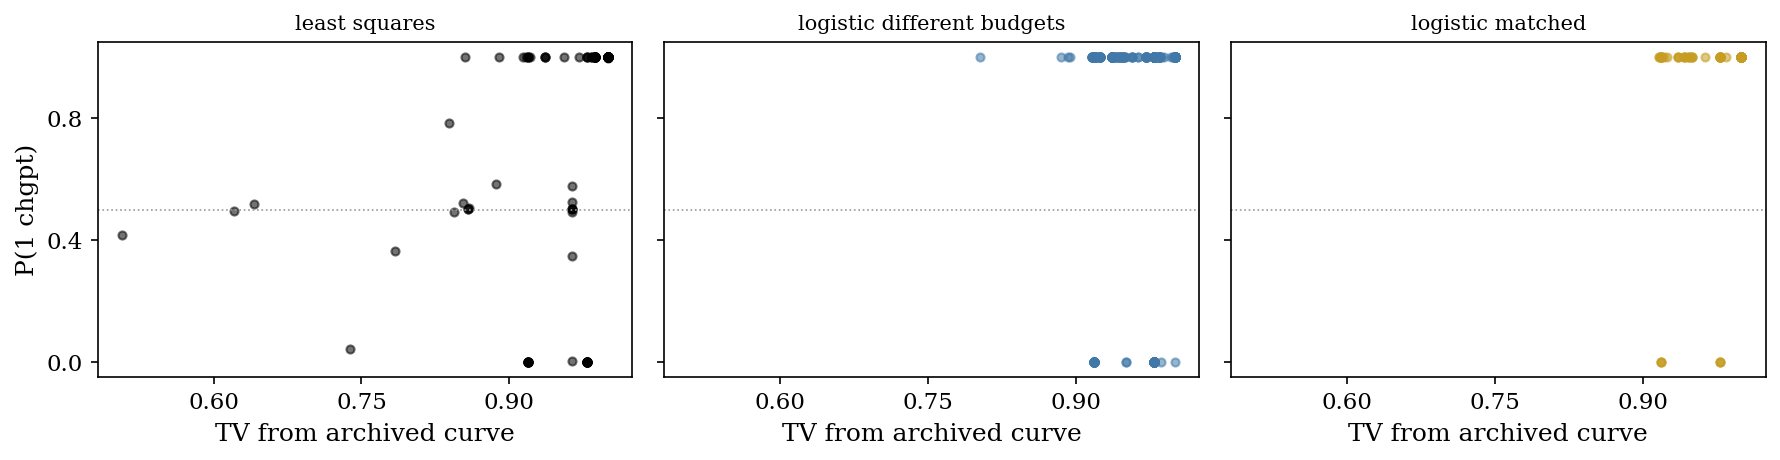

Least-squares auxiliary: iteration-budget sensitivity
Minimum segment size Delta = 1


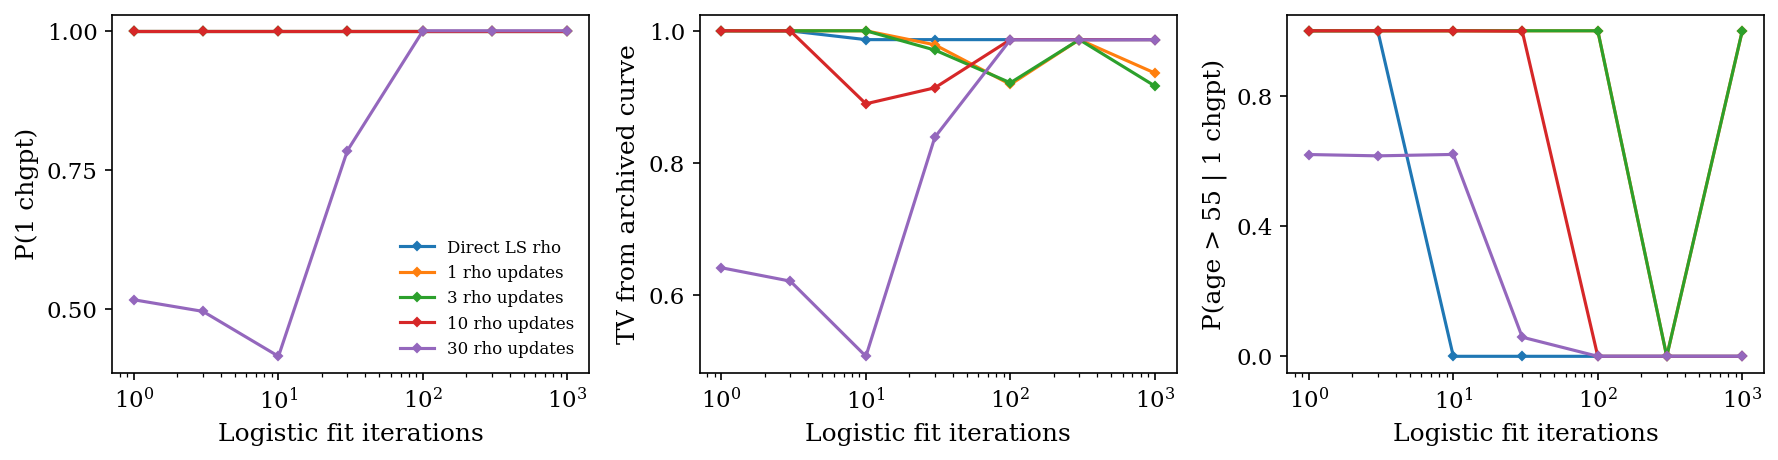

Minimum segment size Delta = 85


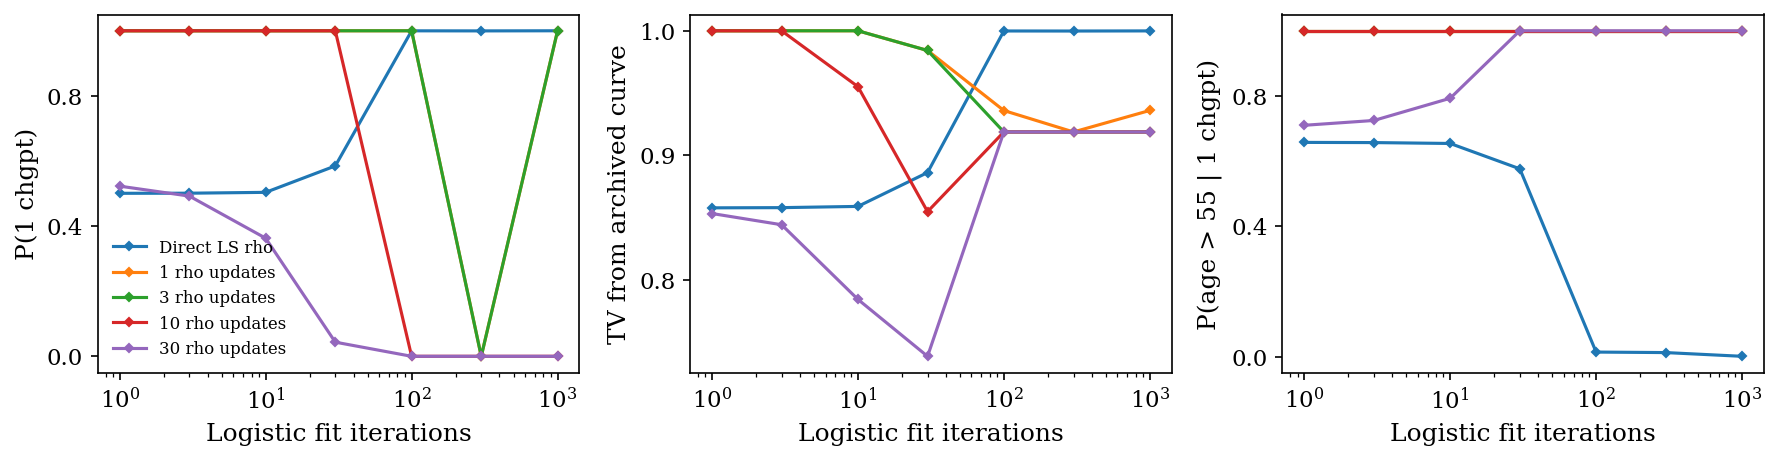

Minimum segment size Delta = 169


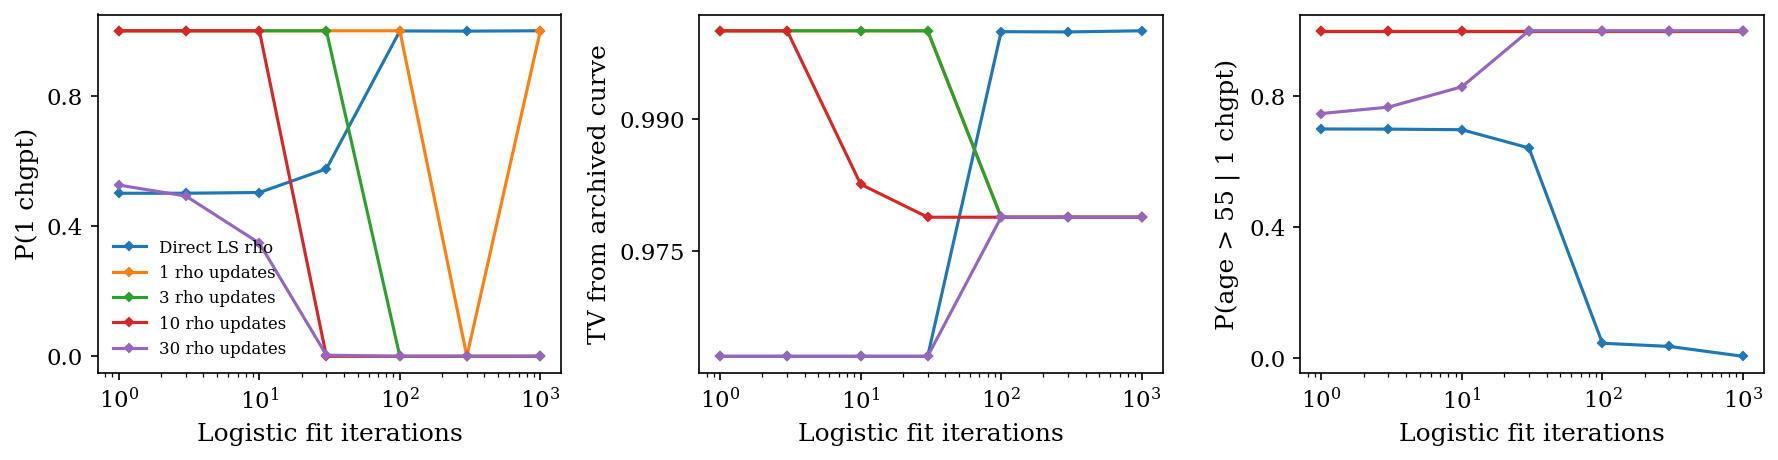

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
                     'axes.labelsize':12,'figure.dpi':150})
colors={'least_squares':'black','logistic_matched':'#c69c22','logistic_different_budgets':'#4178a8'}
print('All settings: shape versus count evidence; primary numerical accuracy only')
fig,axes=plt.subplots(1,3,figsize=(12,3.2),sharex=True,sharey=True)
for ax,(group,data) in zip(axes,summary.groupby('group')):
    ax.scatter(data.TV_to_reference,data.P_1,s=15,alpha=.55,color=colors[group])
    ax.set_title(group.replace('_',' '),fontsize=10)
    ax.set_xlabel('TV from archived curve');ax.axhline(.5,color='0.6',ls=':',lw=.8)
    ax.xaxis.set_major_locator(MaxNLocator(4));ax.yaxis.set_major_locator(MaxNLocator(3))
axes[0].set_ylabel('P(1 chgpt)');fig.tight_layout();plt.show()

print('Least-squares auxiliary: iteration-budget sensitivity')
for delta in DELTAS:
    data=summary[(summary.group=='least_squares')&(summary.Delta==delta)]
    print('Minimum segment size Delta =',delta)
    fig,axes=plt.subplots(1,3,figsize=(12,3.2))
    for updates,sub in data.groupby('rho_updates'):
        sub=sub.sort_values('posterior_budget');label='Direct LS rho' if updates<0 else f'{updates} rho updates'
        for ax,key in zip(axes,('P_1','TV_to_reference','mass_above55')):
            ax.semilogx(sub.posterior_budget,sub[key],'-D',ms=3,label=label)
    for ax,label in zip(axes,('P(1 chgpt)','TV from archived curve','P(age > 55 | 1 chgpt)')):
        ax.set_ylabel(label);ax.set_xlabel('Logistic fit iterations');ax.yaxis.set_major_locator(MaxNLocator(3))
    axes[0].legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()


Refined comparisons: all shortlisted settings, including unfavorable numerical checks
least_squares: Delta=1; auxiliary budget=0; posterior budget=10; rho updates=30
P(1) range 0.4013–0.4063; mean TV=0.4948; moment residual=0.01304


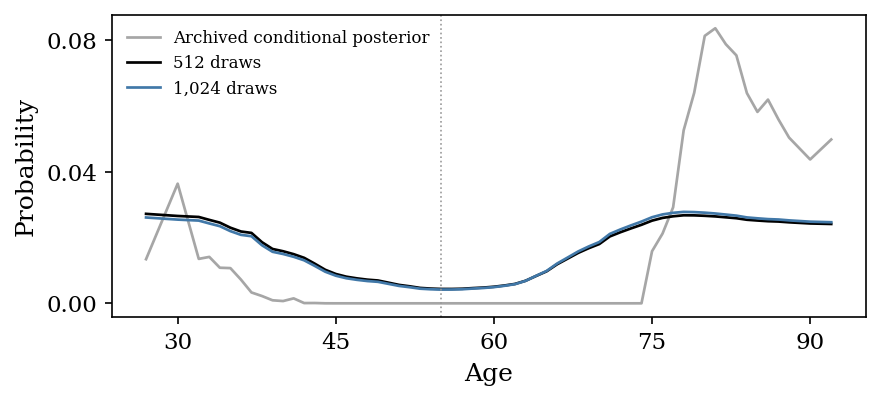

least_squares: Delta=1; auxiliary budget=0; posterior budget=3; rho updates=30
P(1) range 0.4895–0.4955; mean TV=0.6187; moment residual=0.01304


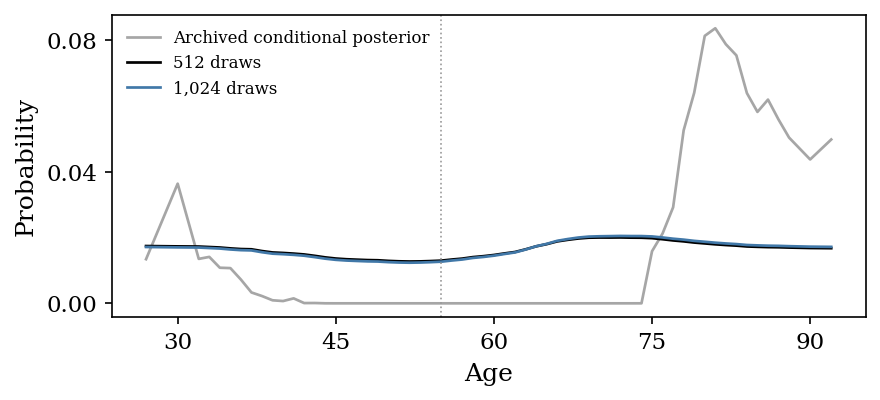

least_squares: Delta=1; auxiliary budget=0; posterior budget=1; rho updates=30
P(1) range 0.5112–0.5188; mean TV=0.6399; moment residual=0.01304


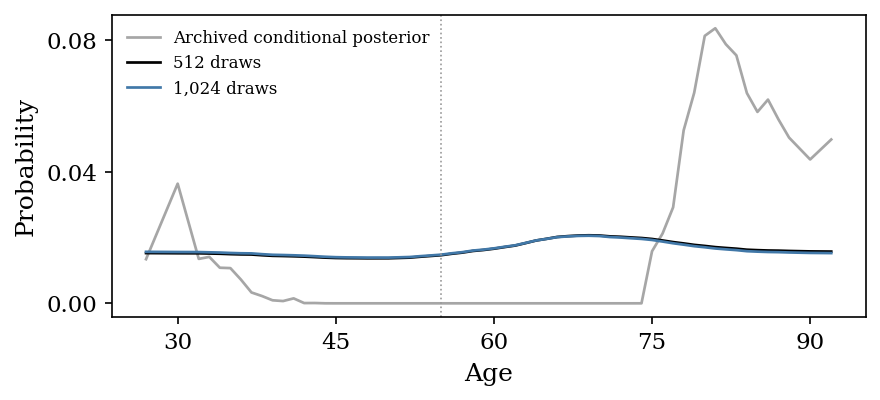

logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8771; moment residual=53.12


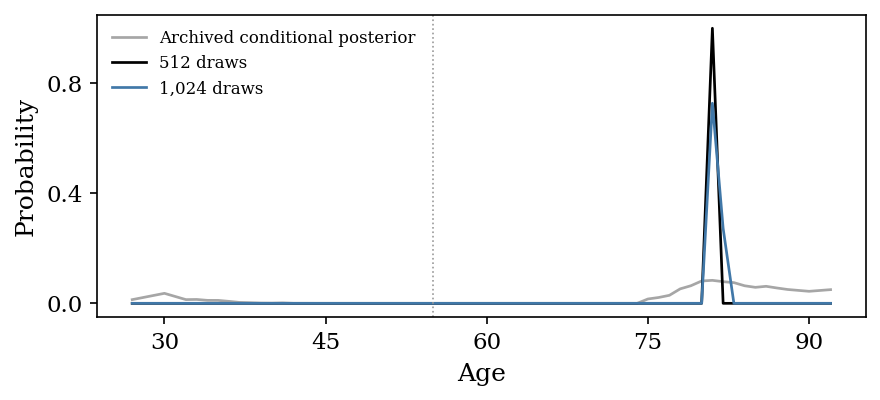

logistic_different_budgets: Delta=1; auxiliary budget=100; posterior budget=1; rho updates=30
P(1) range 1–1; mean TV=0.8851; moment residual=1317


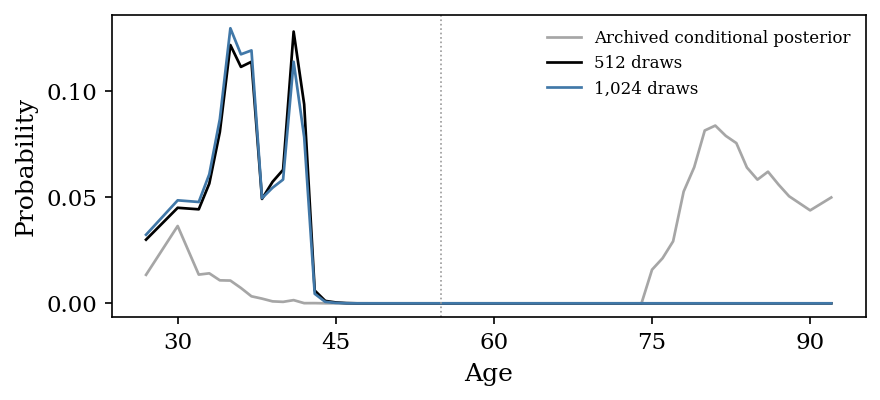

logistic_matched: Delta=85; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8954; moment residual=43.23


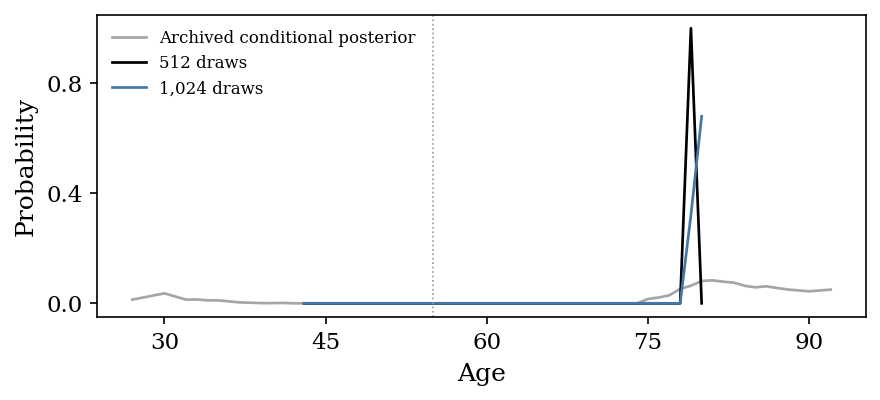

logistic_different_budgets: Delta=1; auxiliary budget=100; posterior budget=1; rho updates=3
P(1) range 1–1; mean TV=0.9037; moment residual=1306


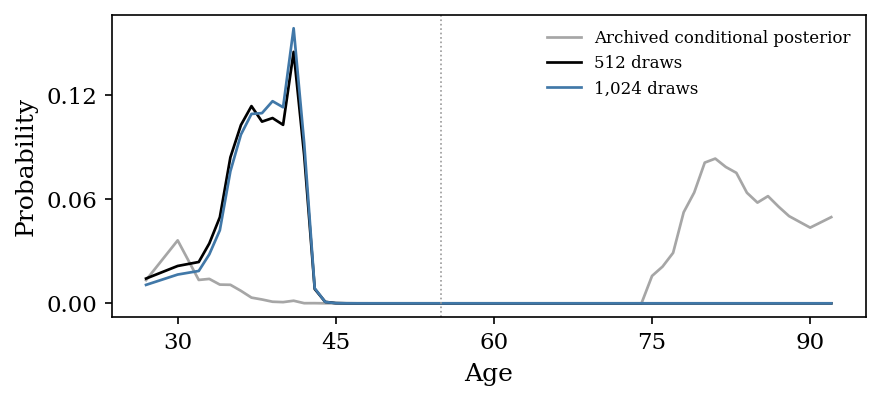

logistic_different_budgets: Delta=85; auxiliary budget=10; posterior budget=30; rho updates=30
P(1) range 1–1; mean TV=0.922; moment residual=0.235


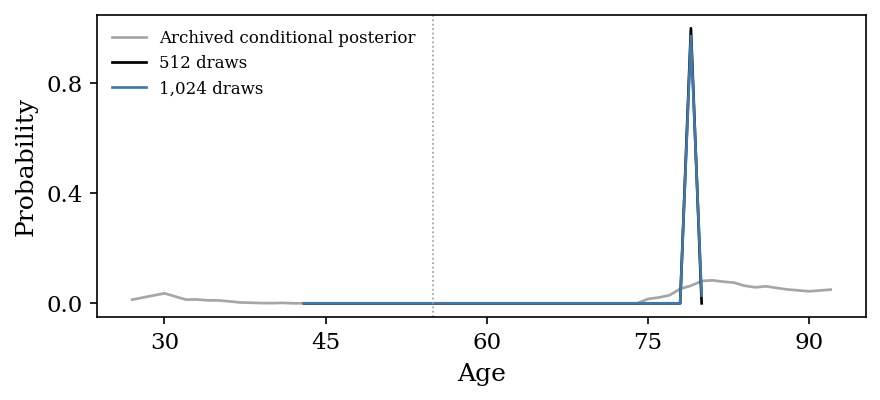

logistic_matched: Delta=1; auxiliary budget=100; posterior budget=100; rho updates=1
P(1) range 1–1; mean TV=0.9274; moment residual=1322


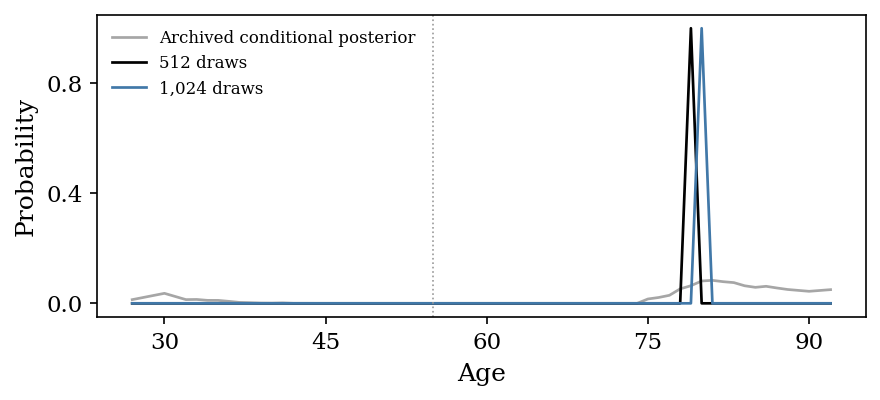

logistic_different_budgets: Delta=1; auxiliary budget=10; posterior budget=100; rho updates=30
P(1) range 1–1; mean TV=0.953; moment residual=0.2993


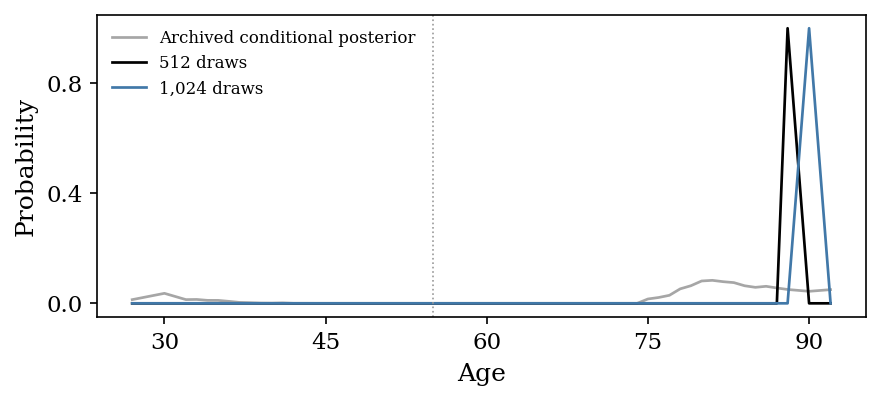

logistic_different_budgets: Delta=85; auxiliary budget=100; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.9842; moment residual=1165


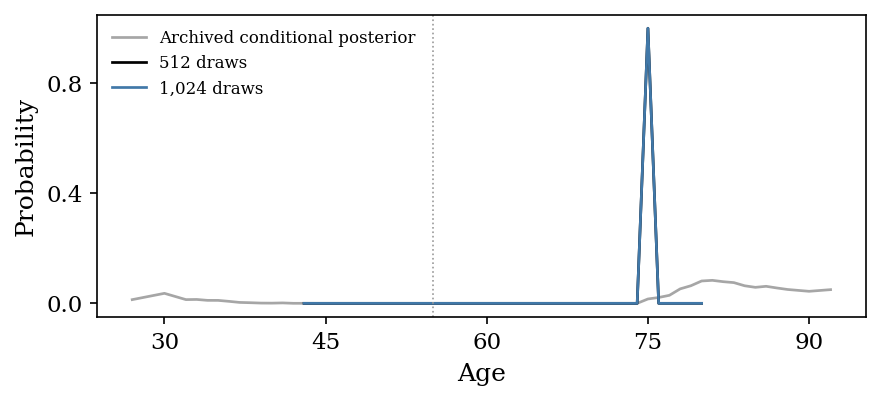

logistic_matched: Delta=169; auxiliary budget=10; posterior budget=10; rho updates=1
P(1) range 1–1; mean TV=1; moment residual=1.075


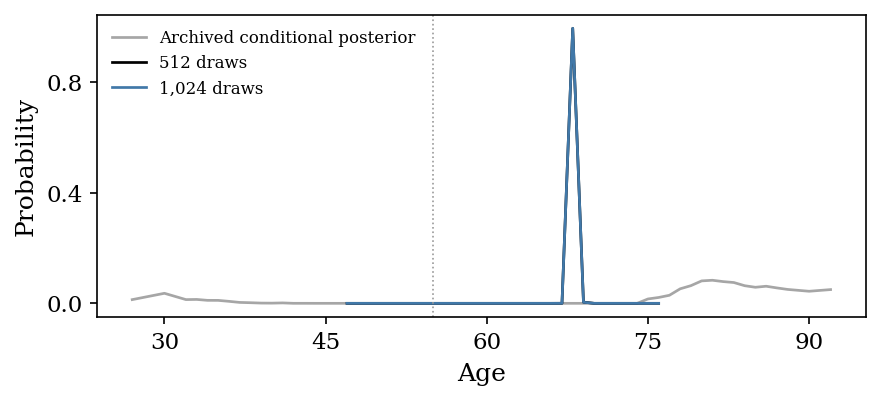

logistic_matched: Delta=85; auxiliary budget=3; posterior budget=3; rho updates=3
P(1) range 1–1; mean TV=1; moment residual=0.2502


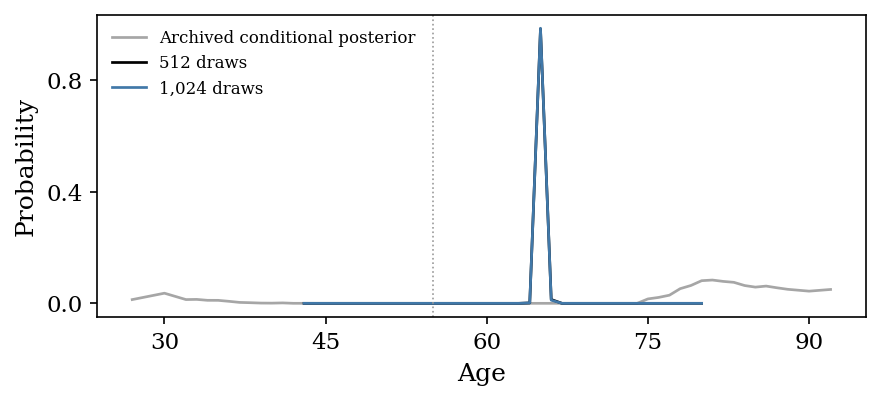

,group,Delta,auxiliary_budget,posterior_budget,rho_updates,tag,P_1,mass_above55,peak_age,interval90_lower,interval90_upper,TV_to_reference,moment_residual,FP_residual_max,fit_kkt_max,coefficient_norm_max
0,least_squares,1,0,10,30,q9_seed42,0.406337,6.327934e-01,27.0,30.0,88.0,0.499693,0.013044,1.147679e-09,0.000202,58.329128
1,least_squares,1,0,3,30,q9_seed42,0.495491,6.159525e-01,72.0,32.0,88.0,0.622118,0.013044,1.147679e-09,0.000219,34.172737
2,least_squares,1,0,1,30,q9_seed42,0.511236,6.266790e-01,69.0,33.0,87.0,0.636909,0.013044,1.147679e-09,0.000489,24.437583
3,least_squares,1,0,10,30,q10_seed123,0.401266,6.506228e-01,78.0,30.0,88.0,0.489956,0.013044,1.188796e-09,0.000202,58.329128
4,least_squares,1,0,3,30,q10_seed123,0.489498,6.253006e-01,72.0,32.0,88.0,0.615345,0.013044,1.188796e-09,0.000219,34.172737
5,least_squares,1,0,1,30,q10_seed123,0.518780,6.193926e-01,69.0,33.0,87.0,0.642866,0.013044,1.188796e-09,0.000489,24.437583
6,logistic_different_budgets,85,100,30,3,q9_seed42,1.000000,1.000000e+00,75.0,75.0,75.0,0.984181,1164.575354,6.145032e-10,0.000151,246.759261
7,logistic_different_budgets,85,100,30,3,q10_seed123,1.000000,1.000000e+00,75.0,75.0,75.0,0.984181,1164.575354,4.676376e-10,0.000151,246.759261
8,logistic_different_budgets,1,100,1,30,q9_seed42,1.000000,5.492913e-70,41.0,30.0,42.0,0.885094,1317.217082,6.108008e-10,0.000489,24.437583
9,logistic_different_budgets,1,100,1,30,q10_seed123,1.000000,1.330201e-71,35.0,30.0,42.0,0.885094,1317.217082,5.120806e-04,0.000489,24.437583


In [4]:
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
print('Refined comparisons: all shortlisted settings, including unfavorable numerical checks')
for row in ranked.itertuples():
    subset=validation[(validation.case==row.case)&(validation.posterior_fit==row.posterior_fit)]
    desc=subset.iloc[0]
    print(f'{row.group}: Delta={desc.Delta}; auxiliary budget={desc.auxiliary_budget}; '
          f'posterior budget={desc.posterior_budget}; rho updates={desc.rho_updates}')
    print(f'P(1) range {row.P1_min:.4g}–{row.P1_max:.4g}; mean TV={row.mean_TV:.4g}; '
          f'moment residual={row.moment_residual:.4g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.65',lw=1.3,label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        saved=pickle.load((root/(row.case+'_'+row.posterior_fit+'_'+tag+'.pkl')).open('rb'))
        ax.plot(saved['ages'],saved['conditional'],color=color,lw=1.3,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True));ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
display(validation[['group','Delta','auxiliary_budget','posterior_budget','rho_updates','tag',
                    'P_1','mass_above55','peak_age','interval90_lower','interval90_upper',
                    'TV_to_reference','moment_residual','FP_residual_max','fit_kkt_max','coefficient_norm_max']])


## Earlier candidates retained for comparison

These historical results are not overwritten by the early-stopping study:

| Auxiliary / posterior-input fit | Intercept | P(1) across two numerical checks | Conditional location |
|---|---|---|---|
| LS / logistic L1 1e-4, 30 rho updates | No | 0.402–0.453 | Mode 79; 79–82% mass above 55; closest earlier no-intercept curve |
| LS / logistic L2 1e-6, 3 rho updates | No | 0.99988–0.99998 | Mode 87; sharper/later than archived curve |
| LS / logistic L2 1e-5, 30 rho updates | No | 0.481–0.484 | Mode 75; diffuse |
| Matched logistic L2 1e-4, 30 rho updates | No | 0.515–0.531 | Mode 65–66; diffuse |
| Logistic auxiliary L1 1e-4 / posterior L2 1.5e-6, 30 updates | Yes | 0.718–0.747 | Mode 81; mean TV 0.291; mismatched families and strengths |
| Logistic auxiliary L1 1e-4 / posterior L1 1e-5, 30 updates | Yes | 0.654–0.680 | Mode 81; mean TV 0.367; mismatched strengths |

All are heuristic and were inspected post hoc. Probability ranges above are not
confidence intervals. Full historical plots and diagnostics remain in the
heuristic, intercept, and exact-matching notebooks.


## Focused follow-up: minimum segment size and optimizer

The broad grid did not clearly improve on the earlier LS/L1 candidate, so this
**post-hoc** follow-up tests $\Delta=1,2,5,10$ and LS rho updates
4, 6, 8, 12, 16, 20, 24, 30, 40, 60. FISTA fitting budgets are
2, 4, 6, 8, 12, 16, 20, 25, 40, 60, 100, 300. An alternative finite-iteration
L-BFGS-B optimizer uses budgets 1, 2, 3, 5, 10, 20, 40, 80; it starts at zero,
has no penalty or intercept, and uses memory 10, at most 20 line-search steps,
and zero gradient/function tolerances (actual termination diagnostics are retained).
Iteration numbers **are not equivalent across optimizers**.

In addition, logistic L-BFGS auxiliary fits with budgets 5, 10, 20 are evaluated
at Delta=1 and 3, 10, 30 rho updates, against every posterior-input fit. Matching
means both optimizer and budget, not just equal iteration numbers. This adds
**980 primary comparisons**, retaining all outcomes. The two closest curves and
the highest-P(1) curve within 0.10 TV of the best in each auxiliary/optimizer class
are rechecked at the same two finer numerical settings as above, with no P(1) cutoff.

Larger Delta can exclude the original curve's upper-age tail: the retained reference
mass is about 84% for Delta=5, 78% for Delta=10, 26% for Delta=85, and 4% for Delta=169.
This lost mass counts against reference similarity; it is not renormalized away.


In [5]:
"""Declared follow-up: smaller Delta, denser LS rho path, optimizer sensitivity.

This post-hoc refinement is retained alongside (not substituted for) the broad
grid. No count-probability threshold is imposed when selecting curve candidates.
"""
from tools.myocardial_finite_iteration_exploration import *

FOCUS_DELTAS=(1,2,5,10)
FOCUS_UPDATES=(4,6,8,12,16,20,24,30,40,60)
FISTA_BUDGETS=(2,4,6,8,12,16,20,25,40,60,100,300)
LBFGS_BUDGETS=(1,2,3,5,10,20,40,80)


def finite_lbfgs_column(X,y,w,budget):
    if isinstance(budget,bool) or int(budget)!=budget or budget<1:
        raise ValueError('positive integer budget required')
    wn=w/w.sum()
    def objective(beta):
        z=X@beta
        return float(wn@(np.logaddexp(0,z)-y*z)), X.T@(wn*(expit(z)-y))
    return minimize(objective,np.zeros(X.shape[1]),jac=True,method='L-BFGS-B',
        options=dict(maxiter=int(budget),ftol=0.,gtol=0.,maxcor=10,maxls=20))


def lbfgs_fit(X,y,phi,budget):
    fitted=[finite_lbfgs_column(X,y,w,budget) for w in phi]
    B=np.column_stack([f.x for f in fitted]);theta=X@B
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    if not np.isfinite(V).all():raise FloatingPointError('Nonfinite adjusted fit')
    return dict(theta=theta,V=V,b=b,coef=B,budget=budget,penalty='none',strength=0.,
        checks=[dict(kkt=float(np.max(abs(f.jac))),iterations=f.nit,success=bool(f.success),
                     norm=float(np.linalg.norm(f.x)),objective=float(f.fun)) for f in fitted])


def prepare_focus(delta,X,y,ages,locations,root):
    path=root/f'fits_delta{delta}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    eta,prior,phi=configuration_prior(len(y),locations[(locations>=delta)&(locations<=len(y)-delta)])
    fits={f'fista{b}':finite_fit(X,y,phi,b) for b in FISTA_BUDGETS}
    fits.update({f'lbfgs{b}':lbfgs_fit(X,y,phi,b) for b in LBFGS_BUDGETS})
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='squared')
    pilot_eta,psi=pilot(theta,y,eta,'squared');S=V.T@V/len(y);rho=np.eye(2);scenarios=[]
    for it in range(1,max(FOCUS_UPDATES)+1):
        state=squared_logistic_state(rho,phi,psi,len(y)/X.shape[1])
        inv=np.linalg.pinv(state['lambda'],rcond=1e-6)
        rho=project_covariance(.75*rho+.25*project_covariance(inv.T@(S-state['kappa'])@inv))
        if it in FOCUS_UPDATES:
            state=squared_logistic_state(rho,phi,psi,len(y)/X.shape[1])
            scenarios.append(dict(rho=rho.copy(),iteration=it,auxiliary='least_squares',loss='squared',
                pilot=pilot_eta,moment_residual=float(np.linalg.norm(state['moment']-S)),state_residual=0.))
    # Alternative implicit regularization in the auxiliary fit too, with exactly
    # matched budget/optimizer indicated in the postprocessing tables.
    if delta==1:
        import WERM.myocardial_approximate as implementation
        old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
        try:
            for budget in (5,10,20):
                fit=fits[f'lbfgs{budget}'];e,psi=pilot(fit['theta'],y,eta,'logistic')
                S=fit['V'].T@fit['V']/len(y)
                scenarios.extend(dict(r,auxiliary=f'lbfgs{budget}',auxiliary_budget=budget,pilot=e,loss='logistic')
                    for r in rho_path(S,phi,psi,len(y)/X.shape[1],'logistic') if r['iteration'] in (3,10,30))
        finally:implementation.logistic_prox=old
    result=dict(delta_min=delta,eta=eta,prior=prior,phi=phi,fits=fits,scenarios=scenarios)
    atomic_save(path,result);print('Focused fits prepared:',delta,flush=True);return result


def with_group(result):
    result=result.copy()
    # For implicit regularization, matching means BOTH optimizer and budget.
    if result['auxiliary']!='least_squares':
        result['group']='logistic_matched' if result['auxiliary']==result['posterior_fit'] else 'logistic_different_budgets'
    result['posterior_optimizer']='lbfgs' if result['posterior_fit'].startswith('lbfgs') else 'fista'
    return result


def run_focus(base):
    X,y,ages,locations=load_data();reference=reference_distribution()
    digest=hashlib.sha256(Path('tools/myocardial_finite_focus.py').read_bytes()).hexdigest()[:12]
    root=base/('focus_'+digest);root.mkdir(exist_ok=True)
    print('Focused checkpoint directory:',root,flush=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        settings_list=Parallel(n_jobs=4)(delayed(prepare_focus)(d,X,y,ages,locations,root) for d in FOCUS_DELTAS)
        settings={s['delta_min']:s for s in settings_list}
        tasks=[(s,r) for s in settings_list for r in s['scenarios']]
        records=Parallel(n_jobs=36)(delayed(evaluate_refined)(dict(s,fits={}),r,X,y,ages,root,8,60) for s,r in tasks)
        results=Parallel(n_jobs=36)(delayed(score_fit)(r,r['states'],settings[r['delta_min']],name,fit,
            X,y,ages,reference,root,'primary') for r in records for name,fit in settings[r['delta_min']]['fits'].items())
    summary=pd.DataFrame([{k:v for k,v in with_group(r).items() if k not in ('conditional','ages','log_likelihood')} for r in results])
    summary.to_csv(root/'summary.csv',index=False)
    chosen=[]
    for (group,optimizer),data in summary.groupby(['group','posterior_optimizer']):
        chosen.extend([data.sort_values('TV_to_reference').head(2),
            data[data.TV_to_reference<=data.TV_to_reference.min()+.1].sort_values('P_1',ascending=False).head(1)])
    selected=pd.concat(chosen).drop_duplicates('label');selected.to_csv(root/'selected_for_validation.csv',index=False)
    by_case={r['label']:r for r in records}
    jobs=[(by_case[c],power,seed) for c in selected.case.unique() for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        states=Parallel(n_jobs=min(36,len(jobs)))(delayed(refined_states)(r,settings[r['delta_min']],len(y),X.shape[1],root,power,seed)
                                              for r,power,seed in jobs)
        checks=Parallel(n_jobs=36)(delayed(score_fit)(r,state,settings[r['delta_min']],row.posterior_fit,
            settings[r['delta_min']]['fits'][row.posterior_fit],X,y,ages,reference,root,f'q{power}_seed{seed}')
            for (r,power,seed),state in zip(jobs,states) for row in selected[selected.case==r['label']].itertuples())
    validation=pd.DataFrame([{k:v for k,v in with_group(r).items() if k not in ('conditional','ages','log_likelihood')} for r in checks])
    validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby(['case','posterior_fit','group'],as_index=False).agg(
        P1_min=('P_1','min'),P1_max=('P_1','max'),mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
        mass_above55_min=('mass_above55','min'),peak_min=('peak_age','min'),peak_max=('peak_age','max'),
        moment_residual=('moment_residual','max')).sort_values('mean_TV')
    ranked.to_csv(root/'ranked.csv',index=False)
    print('FOCUSED EXPLORATION COMPLETE:',len(summary),'primary comparisons.',flush=True)
    print(ranked.to_string(index=False),flush=True);return root




In [6]:
initial_root=root
focused_root=run_focus(initial_root)
root=focused_root
summary=pd.read_csv(root/'summary.csv')
validation=pd.read_csv(root/'validation.csv')
ranked=pd.read_csv(root/'ranked.csv')
display(ranked)


Focused checkpoint directory: results/myocardial_finite_iteration_443c17cf2df6/focus_354ed8f1e782


Completed d5_least_squares_it30_q8_b60


Completed d1_least_squares_it12_q8_b60


Completed d2_least_squares_it16_q8_b60


Completed d2_least_squares_it60_q8_b60


Completed d2_least_squares_it20_q8_b60


... (60 outputs left out)

Numerical validation complete: d1_lbfgs20_it10_q8_b60 10 123


FOCUSED EXPLORATION COMPLETE: 980 primary comparisons.


                         case posterior_fit                      group   P1_min   P1_max  mean_TV   max_TV  mass_above55_min  peak_min  peak_max  moment_residual
 d5_least_squares_it24_q8_b60       fista16              least_squares 0.260890 0.265568 0.169467 0.170571          0.900229      81.0      81.0         0.012968
 d2_least_squares_it20_q8_b60       fista12              least_squares 0.430037 0.437390 0.175996 0.184404          0.934645      80.0      80.0         0.013166
 d2_least_squares_it20_q8_b60       fista16              least_squares 0.463740 0.482719 0.216686 0.227457          0.958396      81.0      81.0         0.013166
 d5_least_squares_it20_q8_b60        lbfgs5              least_squares 0.205679 0.214709 0.248653 0.248909          0.900969      84.0      84.0         0.013100
d10_least_squares_it20_q8_b60        lbfgs5              least_squares 0.201833 0.205649 0.266246 0.270968          0.947663      83.0      83.0         0.013068
 d2_least_squares_it16_q8_b6

,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual
0,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,0.900229,81.0,81.0,0.012968
1,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,0.934645,80.0,80.0,0.013166
2,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,0.958396,81.0,81.0,0.013166
3,d5_least_squares_it20_q8_b60,lbfgs5,least_squares,0.205679,0.214709,0.248653,0.248909,0.900969,84.0,84.0,0.013100
4,d10_least_squares_it20_q8_b60,lbfgs5,least_squares,0.201833,0.205649,0.266246,0.270968,0.947663,83.0,83.0,0.013068
5,d2_least_squares_it16_q8_b60,lbfgs5,least_squares,0.305700,0.316399,0.305304,0.321317,0.921749,84.0,84.0,0.013583
6,d1_lbfgs5_it10_q8_b60,lbfgs80,logistic_different_budgets,1.000000,1.000000,0.916440,0.916440,1.000000,81.0,81.0,1.368949
7,d1_lbfgs10_it3_q8_b60,fista25,logistic_different_budgets,1.000000,1.000000,0.922197,0.935922,1.000000,79.0,79.0,557.792438
8,d1_lbfgs20_it3_q8_b60,lbfgs40,logistic_different_budgets,1.000000,1.000000,0.943886,0.949658,1.000000,86.0,88.0,1177.985361
9,d1_lbfgs20_it10_q8_b60,fista25,logistic_different_budgets,1.000000,1.000000,0.947441,0.947442,1.000000,78.0,78.0,1181.471756


Refined comparisons: all shortlisted settings, including unfavorable numerical checks
least_squares: Delta=5; auxiliary budget=0; posterior budget=16; rho updates=24
P(1) range 0.2609–0.2656; mean TV=0.1695; moment residual=0.01297


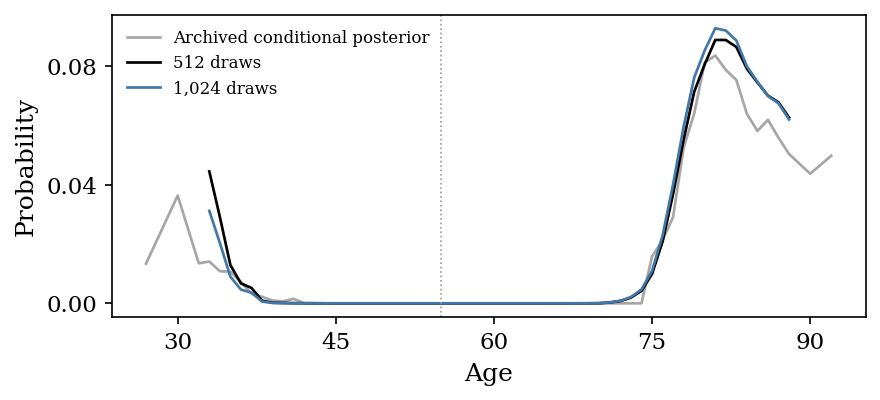

least_squares: Delta=2; auxiliary budget=0; posterior budget=12; rho updates=20
P(1) range 0.43–0.4374; mean TV=0.176; moment residual=0.01317


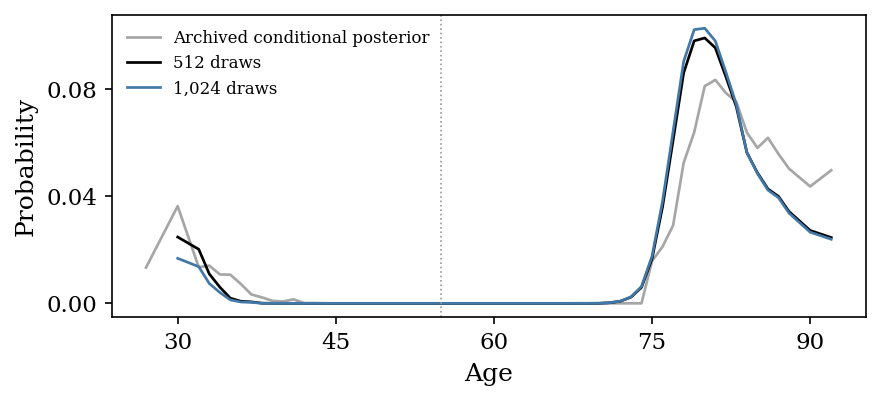

least_squares: Delta=2; auxiliary budget=0; posterior budget=16; rho updates=20
P(1) range 0.4637–0.4827; mean TV=0.2167; moment residual=0.01317


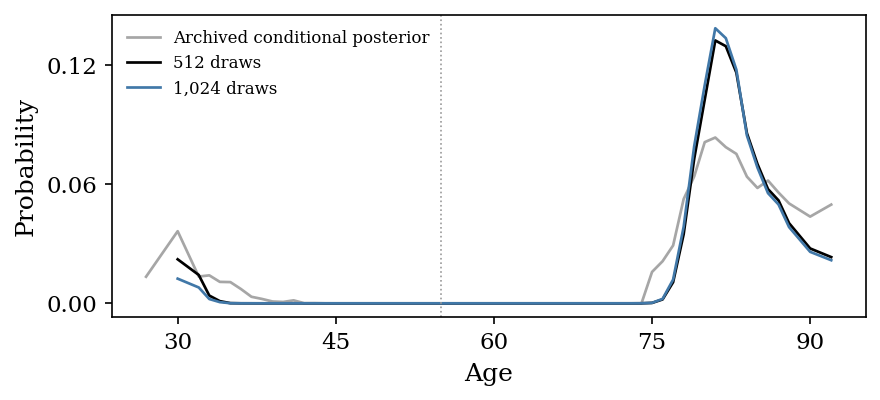

least_squares: Delta=5; auxiliary budget=0; posterior budget=5; rho updates=20
P(1) range 0.2057–0.2147; mean TV=0.2487; moment residual=0.0131


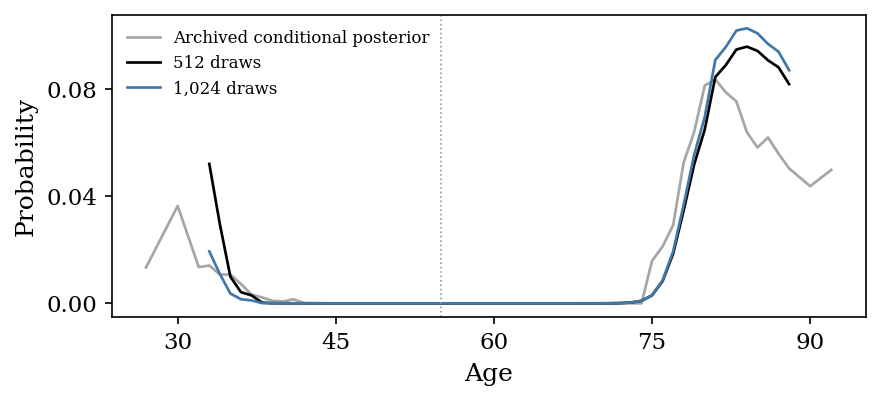

least_squares: Delta=10; auxiliary budget=0; posterior budget=5; rho updates=20
P(1) range 0.2018–0.2056; mean TV=0.2662; moment residual=0.01307


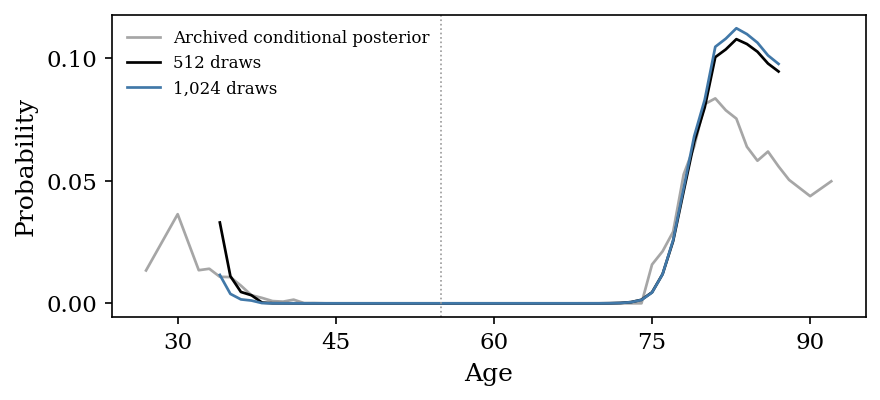

least_squares: Delta=2; auxiliary budget=0; posterior budget=5; rho updates=16
P(1) range 0.3057–0.3164; mean TV=0.3053; moment residual=0.01358


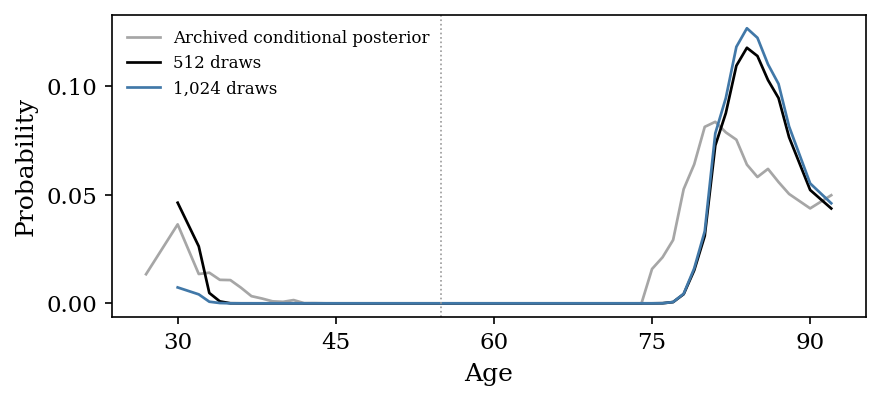

logistic_different_budgets: Delta=1; auxiliary budget=5; posterior budget=80; rho updates=10
P(1) range 1–1; mean TV=0.9164; moment residual=1.369


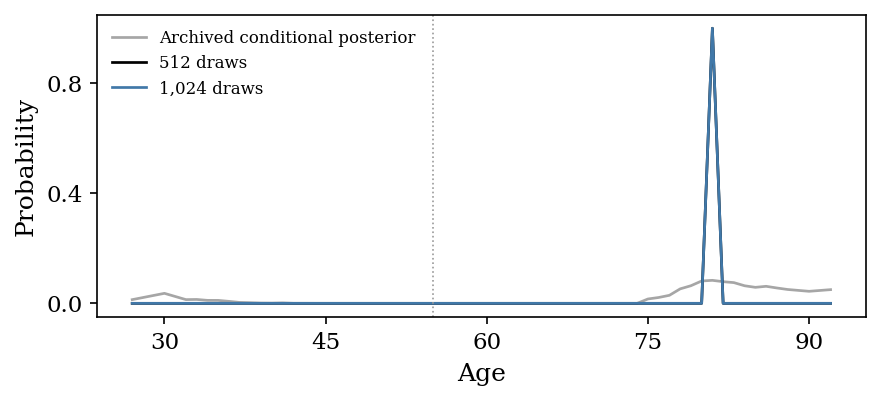

logistic_different_budgets: Delta=1; auxiliary budget=10; posterior budget=25; rho updates=3
P(1) range 1–1; mean TV=0.9222; moment residual=557.8


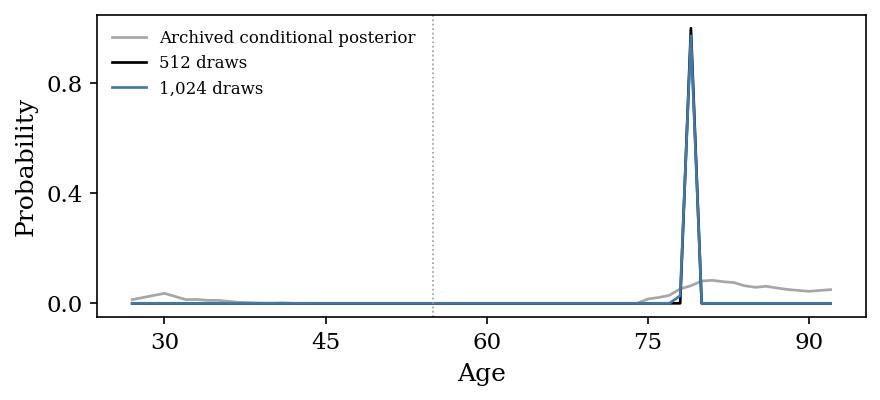

logistic_different_budgets: Delta=1; auxiliary budget=20; posterior budget=40; rho updates=3
P(1) range 1–1; mean TV=0.9439; moment residual=1178


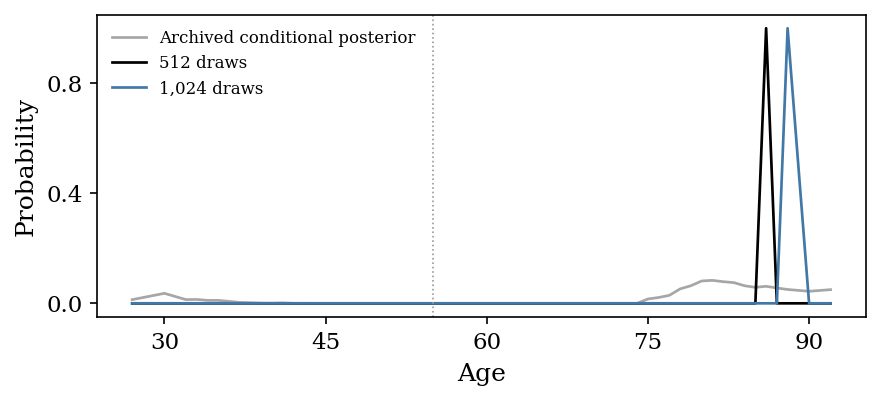

logistic_different_budgets: Delta=1; auxiliary budget=20; posterior budget=25; rho updates=10
P(1) range 1–1; mean TV=0.9474; moment residual=1181


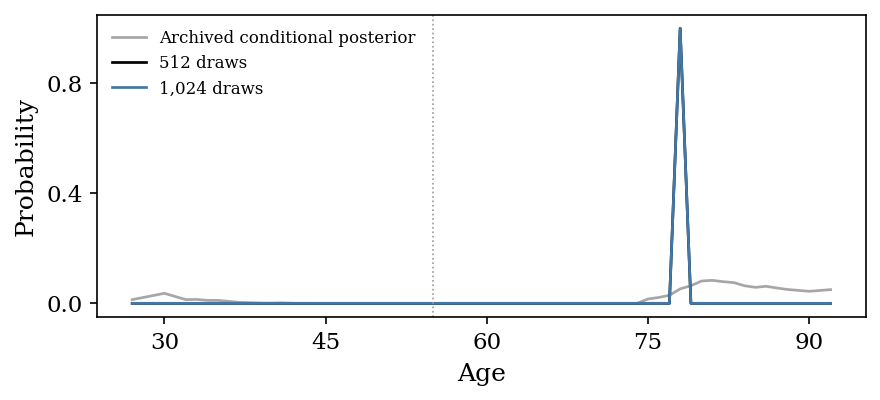

logistic_different_budgets: Delta=1; auxiliary budget=20; posterior budget=80; rho updates=10
P(1) range 1–1; mean TV=0.9491; moment residual=1181


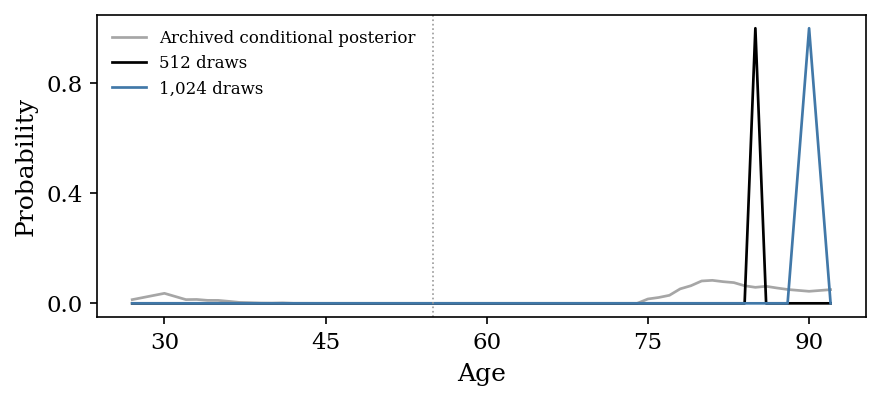

logistic_different_budgets: Delta=1; auxiliary budget=10; posterior budget=20; rho updates=30
P(1) range 1–1; mean TV=0.9788; moment residual=557.5


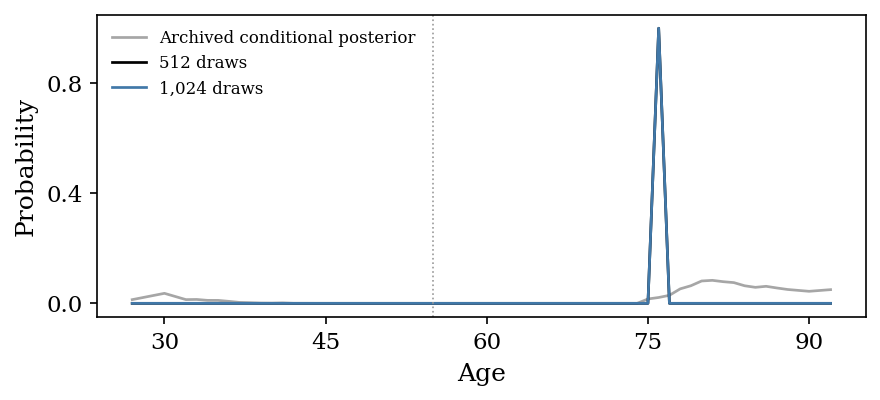

logistic_matched: Delta=1; auxiliary budget=20; posterior budget=20; rho updates=10
P(1) range 1–1; mean TV=0.9893; moment residual=1181


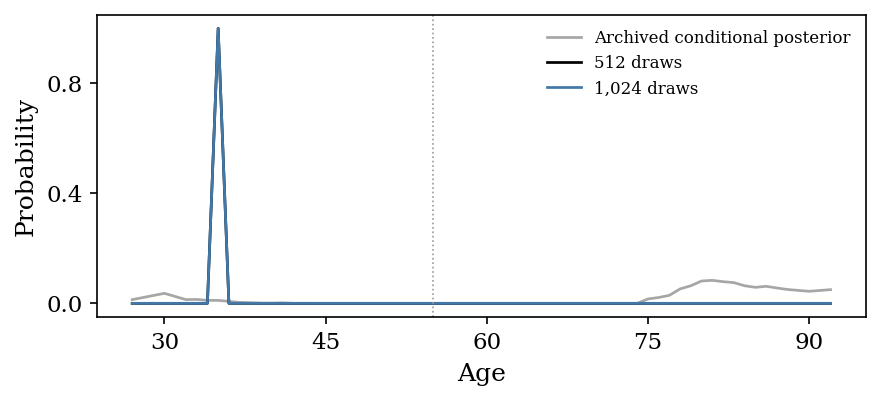

logistic_matched: Delta=1; auxiliary budget=20; posterior budget=20; rho updates=30
P(1) range 1–1; mean TV=0.9893; moment residual=1182


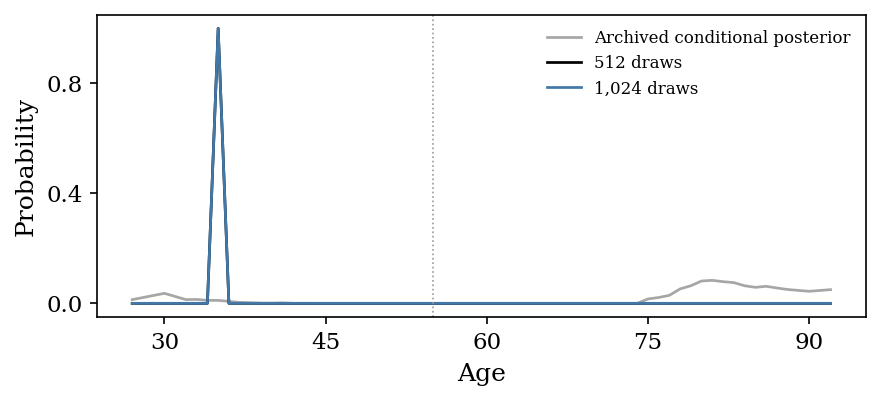

logistic_matched: Delta=1; auxiliary budget=10; posterior budget=10; rho updates=10
P(1) range 1–1; mean TV=0.9972; moment residual=557.5


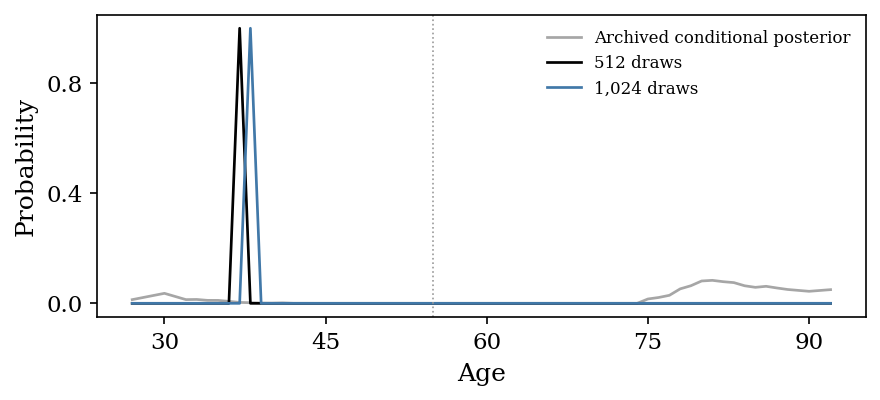

,group,Delta,auxiliary_budget,posterior_budget,rho_updates,tag,P_1,mass_above55,peak_age,interval90_lower,interval90_upper,TV_to_reference,moment_residual,FP_residual_max,fit_kkt_max,coefficient_norm_max
0,least_squares,5,0,16,24,q9_seed42,0.260890,0.900229,81.0,34.0,88.0,0.168362,0.012968,1.274042e-09,0.000190,99.585816
1,least_squares,5,0,16,24,q10_seed123,0.265568,0.930363,81.0,34.0,88.0,0.170571,0.012968,1.353565e-09,0.000190,99.585816
2,least_squares,2,0,12,20,q9_seed42,0.430037,0.934645,80.0,33.0,90.0,0.167588,0.013166,1.093602e-09,0.000199,70.000885
3,least_squares,2,0,16,20,q9_seed42,0.463740,0.958396,81.0,77.0,90.0,0.205915,0.013166,1.093602e-09,0.000190,100.126416
4,least_squares,2,0,12,20,q10_seed123,0.437390,0.955815,80.0,74.0,90.0,0.184404,0.013166,1.107784e-09,0.000199,70.000885
5,least_squares,2,0,16,20,q10_seed123,0.482719,0.976744,81.0,78.0,88.0,0.227457,0.013166,1.107784e-09,0.000190,100.126416
6,least_squares,5,0,5,20,q9_seed42,0.214709,0.900969,84.0,33.0,88.0,0.248909,0.013100,1.296206e-09,0.000269,72.175701
7,least_squares,5,0,5,20,q10_seed123,0.205679,0.963266,84.0,77.0,88.0,0.248397,0.013100,1.318178e-09,0.000269,72.175701
8,least_squares,10,0,5,20,q9_seed42,0.205649,0.947663,83.0,37.0,87.0,0.261525,0.013068,2.455774e-09,0.000269,72.218967
9,least_squares,10,0,5,20,q10_seed123,0.201833,0.981712,83.0,77.0,87.0,0.270968,0.013068,2.346660e-09,0.000269,72.218967


In [7]:
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
print('Refined comparisons: all shortlisted settings, including unfavorable numerical checks')
for row in ranked.itertuples():
    subset=validation[(validation.case==row.case)&(validation.posterior_fit==row.posterior_fit)]
    desc=subset.iloc[0]
    print(f'{row.group}: Delta={desc.Delta}; auxiliary budget={desc.auxiliary_budget}; '
          f'posterior budget={desc.posterior_budget}; rho updates={desc.rho_updates}')
    print(f'P(1) range {row.P1_min:.4g}–{row.P1_max:.4g}; mean TV={row.mean_TV:.4g}; '
          f'moment residual={row.moment_residual:.4g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.65',lw=1.3,label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        saved=pickle.load((root/(row.case+'_'+row.posterior_fit+'_'+tag+'.pkl')).open('rb'))
        ax.plot(saved['ages'],saved['conditional'],color=color,lw=1.3,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True));ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
display(validation[['group','Delta','auxiliary_budget','posterior_budget','rho_updates','tag',
                    'P_1','mass_above55','peak_age','interval90_lower','interval90_upper',
                    'TV_to_reference','moment_residual','FP_residual_max','fit_kkt_max','coefficient_norm_max']])


In [8]:
print('Combined finite-iteration shortlist: both sweeps, with numerical sensitivity')
combined=[]
for stage,folder in [('broad',initial_root),('focused',focused_root)]:
    table=pd.read_csv(folder/'ranked.csv')
    for row in table.to_dict('records'):
        recs=[pickle.load((folder/(row['case']+'_'+row['posterior_fit']+'_'+tag+'.pkl')).open('rb'))
              for tag in ('q9_seed42','q10_seed123')]
        row.update(stage=stage,Delta=recs[0]['Delta'],auxiliary=recs[0]['auxiliary'],
            auxiliary_budget=recs[0]['auxiliary_budget'],posterior_budget=recs[0]['posterior_budget'],
            rho_updates=recs[0]['rho_updates'],
            numerical_curve_TV=.5*np.abs(recs[0]['conditional']-recs[1]['conditional']).sum(),
            min_interval90_width=min(r['interval90_upper']-r['interval90_lower'] for r in recs),
            max_interval90_width=max(r['interval90_upper']-r['interval90_lower'] for r in recs))
        combined.append(row)
combined=pd.DataFrame(combined).sort_values('mean_TV')
combined.to_csv(initial_root/'combined_checked_candidates.csv',index=False)
display(combined)
print('These are exploratory comparisons, not independently validated model choices.')


Combined finite-iteration shortlist: both sweeps, with numerical sensitivity


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual,stage,Delta,auxiliary,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width
13,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,0.012968,focused,5,least_squares,0,16,24,3.130377e-02,54.0,54.0
14,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,0.013166,focused,2,least_squares,0,12,20,2.424608e-02,16.0,57.0
15,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,0.013166,focused,2,least_squares,0,16,20,3.062949e-02,10.0,13.0
16,d5_least_squares_it20_q8_b60,lbfgs5,least_squares,0.205679,0.214709,0.248653,0.248909,9.009691e-01,84.0,84.0,0.013100,focused,5,least_squares,0,5,20,6.232307e-02,11.0,55.0
17,d10_least_squares_it20_q8_b60,lbfgs5,least_squares,0.201833,0.205649,0.266246,0.270968,9.476632e-01,83.0,83.0,0.013068,focused,10,least_squares,0,5,20,3.427498e-02,10.0,50.0
18,d2_least_squares_it16_q8_b60,lbfgs5,least_squares,0.305700,0.316399,0.305304,0.321317,9.217486e-01,84.0,84.0,0.013583,focused,2,least_squares,0,5,16,6.591722e-02,10.0,58.0
0,d1_least_squares_it30_q8_b60,early10,least_squares,0.401266,0.406337,0.494824,0.499693,6.327934e-01,27.0,78.0,0.013044,broad,1,least_squares,0,10,30,1.873924e-02,58.0,58.0
1,d1_least_squares_it30_q8_b60,early3,least_squares,0.489498,0.495491,0.618732,0.622118,6.159525e-01,72.0,72.0,0.013044,broad,1,least_squares,0,3,30,1.101070e-02,56.0,56.0
2,d1_least_squares_it30_q8_b60,early1,least_squares,0.511236,0.518780,0.639888,0.642866,6.193926e-01,69.0,69.0,0.013044,broad,1,least_squares,0,1,30,8.183063e-03,54.0,54.0
3,d1_early30_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,53.119463,broad,1,early30,30,30,3,2.725689e-01,0.0,1.0


These are exploratory comparisons, not independently validated model choices.


## Initialization sensitivity: finite logistic in both stages

To test whether a favorable result depends on the starting covariance, use the
explicit symmetric family
$$\rho^{(0)}=s\begin{pmatrix}1&r\\r&1\end{pmatrix},\qquad
s\in\{0.1,1,10\},\quad r\in\{-0.5,0,0.5\}.$$
All nine starts are positive definite and the identity is included. These are
generic scale/correlation perturbations, not matrices fitted to the archived curve.
The grid is disclosed in full rather than presenting a selected start as a default.

Both fitting stages are unpenalized, finite-iteration logistic FISTA with no
intercept. Auxiliary budgets are 1, 3, 10, 30, rho updates are 1, 3, 10, and
posterior-input budgets are the original seven values. Delta is fixed at 1 to retain
the complete archived age support. This gives **756 primary comparisons**. Identity
states are reused only after exact covariance and age-grid checks.

The two closest curves and the highest-P(1) curve within 0.10 TV of the best in each
matched/different-budget class are checked at finer numerical accuracy. The best
matched-budget candidate is additionally checked at neighboring starts and the
identity baseline. A favorable isolated start is not evidence of robustness.
P(1) near or above 0.5 and a reference-like shape are exploratory objectives, not
acceptance constraints imposed on the reported results. All prior/model/normalization
choices remain unchanged.


In [9]:
"""Transparent rho-initialization sensitivity for finite logistic/logistic fits."""
from tools.myocardial_finite_iteration_exploration import *


def initialization_grid():
    return [(f'scale{s:g}_corr{r:g}',s*np.array([[1.,r],[r,1.]]))
            for s in (.1,1.,10.) for r in (-.5,0.,.5)]


def prepare_initialization(base,budget,name,initial,X,y,root):
    path=root/f'aux_early{budget}_{name}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    source=pickle.load((base/f'aux_d1_early{budget}.pkl').open('rb'))
    setting=pickle.load((SOURCE/'fits_delta1.pkl').open('rb'))
    if np.array_equal(initial,np.eye(2)):
        scenarios=[dict(r) for r in source['scenarios'] if r['iteration'] in (1,3,10)]
    else:
        fit=source['fit'];S=fit['V'].T@fit['V']/len(y)
        e,psi=pilot(fit['theta'],y,setting['eta'],'logistic');rho=initial.copy();scenarios=[]
        import WERM.myocardial_approximate as implementation
        old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
        try:
            for iteration in range(1,11):
                state=implementation.logistic_state(rho,setting['phi'],psi,len(y)/X.shape[1],sample_power=7,max_nfev=30)
                inv=np.linalg.pinv(state['lambda'],rcond=1e-6)
                rho=project_covariance(.75*rho+.25*project_covariance(inv.T@(S-state['kappa'])@inv))
                if iteration in (1,3,10):
                    check=implementation.logistic_state(rho,setting['phi'],psi,len(y)/X.shape[1],sample_power=8,max_nfev=60)
                    scenarios.append(dict(rho=rho.copy(),iteration=iteration,pilot=e,loss='logistic',
                        moment_residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S)),
                        state_residual=check['training_residual']))
        finally:implementation.logistic_prox=old
    for r in scenarios:
        r.update(auxiliary=f'early{budget}_init_{name}',auxiliary_budget=budget,
                 initialization_name=name,initial_rho=initial)
    atomic_save(path,scenarios);print('Initialization path ready:',budget,name,flush=True)
    return scenarios


def run_initializations(base):
    X,y,ages,locations=load_data();reference=reference_distribution()
    digest=hashlib.sha256(Path('tools/myocardial_initialization_sweep.py').read_bytes()).hexdigest()[:12]
    root=base/('initializations_'+digest);root.mkdir(exist_ok=True)
    setting=pickle.load((SOURCE/'fits_delta1.pkl').open('rb'))
    setting=dict(setting,fits={f'early{b}':pickle.load((base/f'aux_d1_early{b}.pkl').open('rb'))['fit'] for b in FIT_BUDGETS})
    print('Initialization sensitivity directory:',root,flush=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=36)(delayed(prepare_initialization)(base,b,name,initial,X,y,root)
                    for b in (1,3,10,30) for name,initial in initialization_grid())
        scenarios=[r for group in prepared for r in group]
        # Reuse identity-start states from the broad sweep only after exact
        # rho/age-grid equality. Other starts get their own checkpoints.
        for r in scenarios:
            if not np.array_equal(r['initial_rho'],np.eye(2)):continue
            old_label=f"d1_early{r['auxiliary_budget']}_it{r['iteration']}_q8_b60"
            old=pickle.load((base/(old_label+'.pkl')).open('rb'))
            assert np.array_equal(old['scenario']['rho'],r['rho'])
            assert np.array_equal(old['eta'],setting['eta'])
            label=f"d1_{r['auxiliary']}_it{r['iteration']}_q8_b60"
            if not (root/(label+'.pkl')).exists():atomic_save(root/(label+'.pkl'),dict(old,label=label,scenario=r))
            for power,seed in ((9,42),(10,123)):
                src=base/(old_label+f'_states_q{power}_seed{seed}.pkl')
                dst=root/(label+f'_states_q{power}_seed{seed}.pkl')
                if src.exists() and not dst.exists():atomic_save(dst,pickle.load(src.open('rb')))
        records=Parallel(n_jobs=36)(delayed(evaluate_refined)(dict(setting,fits={}),r,X,y,ages,root,8,60) for r in scenarios)
        results=Parallel(n_jobs=36)(delayed(score_fit)(r,r['states'],setting,name,fit,X,y,ages,reference,root,'primary')
                    for r in records for name,fit in setting['fits'].items())
    case_map={r['label']:r for r in records}
    def tabulate(results):
        rows=[]
        for result in results:
            row={k:v for k,v in result.items() if k not in ('conditional','ages','log_likelihood')}
            scenario=case_map[row['case']]['scenario'];rho0=scenario['initial_rho']
            row.update(initialization=scenario['initialization_name'],initial_scale=rho0[0,0],initial_correlation=rho0[0,1]/rho0[0,0])
            rows.append(row)
        return pd.DataFrame(rows)
    summary=tabulate(results);summary.to_csv(root/'summary.csv',index=False)
    selected=[]
    for group,data in summary.groupby('group'):
        selected.extend([data.sort_values('TV_to_reference').head(2),
            data[data.TV_to_reference<=data.TV_to_reference.min()+.1].sort_values('P_1',ascending=False).head(1)])
    # Test neighboring starts for the best matched-budget candidate; do not
    # assume an isolated favorable initialization is robust.
    best=summary[summary.group=='logistic_matched'].sort_values('TV_to_reference').iloc[0]
    neighbors=summary[(summary.auxiliary_budget==best.auxiliary_budget)&
        (summary.posterior_budget==best.posterior_budget)&(summary.rho_updates==best.rho_updates)].copy()
    neighbors['distance']=abs(np.log10(neighbors.initial_scale/best.initial_scale))+abs(neighbors.initial_correlation-best.initial_correlation)
    selected.append(neighbors.sort_values('distance').head(3).drop(columns='distance'))
    selected.append(neighbors[(neighbors.initial_scale==1)&(neighbors.initial_correlation==0)].drop(columns='distance'))
    selected=pd.concat(selected).drop_duplicates('label');selected.to_csv(root/'selected_for_validation.csv',index=False)
    jobs=[(case_map[c],power,seed) for c in selected.case.unique() for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        states=Parallel(n_jobs=min(36,len(jobs)))(delayed(refined_states)(r,setting,len(y),X.shape[1],root,power,seed) for r,power,seed in jobs)
        results=Parallel(n_jobs=36)(delayed(score_fit)(r,state,setting,row.posterior_fit,setting['fits'][row.posterior_fit],
            X,y,ages,reference,root,f'q{power}_seed{seed}') for (r,power,seed),state in zip(jobs,states)
            for row in selected[selected.case==r['label']].itertuples())
    validation=tabulate(results);validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby(['case','posterior_fit','group','initialization'],as_index=False).agg(
        P1_min=('P_1','min'),P1_max=('P_1','max'),mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
        mass_above55_min=('mass_above55','min'),peak_min=('peak_age','min'),peak_max=('peak_age','max'),
        moment_residual=('moment_residual','max')).sort_values('mean_TV')
    ranked.to_csv(root/'ranked.csv',index=False)
    print('INITIALIZATION STUDY COMPLETE:',len(summary),'primary comparisons.',flush=True)
    print(ranked.to_string(index=False),flush=True);return root




In [10]:
initialization_root=run_initializations(initial_root)
root=initialization_root
summary=pd.read_csv(root/'summary.csv')
validation=pd.read_csv(root/'validation.csv')
ranked=pd.read_csv(root/'ranked.csv')
display(ranked)


Initialization sensitivity directory: results/myocardial_finite_iteration_443c17cf2df6/initializations_08d005a910b5


Initialization path ready: 3 scale1_corr0
Initialization path ready: 10 scale1_corr0
Initialization path ready: 30 scale1_corr0


Initialization path ready: 1 scale1_corr0


Initialization path ready: 3 scale1_corr0.5


Initialization path ready: 1 scale10_corr-0.5
Initialization path ready: 3 scale1_corr-0.5


Initialization path ready: 3 scale10_corr0


... (120 outputs left out)

Numerical validation complete: d1_early30_init_scale10_corr0_it3_q8_b60 10 123


INITIALIZATION STUDY COMPLETE: 756 primary comparisons.


                                       case posterior_fit                      group    initialization  P1_min  P1_max  mean_TV   max_TV  mass_above55_min  peak_min  peak_max  moment_residual
   d1_early30_init_scale10_corr0_it3_q8_b60       early30           logistic_matched     scale10_corr0     1.0     1.0 0.877078 0.916425               1.0      81.0      81.0        52.878998
    d1_early30_init_scale1_corr0_it3_q8_b60       early30           logistic_matched      scale1_corr0     1.0     1.0 0.877085 0.916439               1.0      81.0      81.0        53.119463
 d1_early30_init_scale1_corr-0.5_it3_q8_b60       early30           logistic_matched   scale1_corr-0.5     1.0     1.0 0.877085 0.916440               1.0      81.0      81.0        53.117226
  d1_early30_init_scale0.1_corr0_it3_q8_b60       early30           logistic_matched    scale0.1_corr0     1.0     1.0 0.884771 0.916383               1.0      81.0      81.0        53.109644
d1_early30_init_scale10_corr-0.5_it3_q8_

,case,posterior_fit,group,initialization,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual
0,d1_early30_init_scale10_corr0_it3_q8_b60,early30,logistic_matched,scale10_corr0,1.0,1.0,0.877078,0.916425,1.0,81.0,81.0,52.878998
1,d1_early30_init_scale1_corr0_it3_q8_b60,early30,logistic_matched,scale1_corr0,1.0,1.0,0.877085,0.916439,1.0,81.0,81.0,53.119463
2,d1_early30_init_scale1_corr-0.5_it3_q8_b60,early30,logistic_matched,scale1_corr-0.5,1.0,1.0,0.877085,0.916440,1.0,81.0,81.0,53.117226
3,d1_early30_init_scale0.1_corr0_it3_q8_b60,early30,logistic_matched,scale0.1_corr0,1.0,1.0,0.884771,0.916383,1.0,81.0,81.0,53.109644
4,d1_early30_init_scale10_corr-0.5_it3_q8_b60,early30,logistic_matched,scale10_corr-0.5,1.0,1.0,0.907095,0.919658,1.0,81.0,82.0,53.393746
5,d1_early3_init_scale0.1_corr0.5_it10_q8_b60,early100,logistic_different_budgets,scale0.1_corr0.5,1.0,1.0,0.917598,0.918756,1.0,80.0,81.0,0.084463
6,d1_early1_init_scale10_corr0_it10_q8_b60,early300,logistic_different_budgets,scale10_corr0,1.0,1.0,0.922985,0.924679,1.0,82.0,83.0,0.803125
7,d1_early30_init_scale10_corr0.5_it1_q8_b60,early30,logistic_matched,scale10_corr0.5,1.0,1.0,0.927186,0.935615,1.0,79.0,80.0,52.440799
8,d1_early1_init_scale0.1_corr-0.5_it1_q8_b60,early100,logistic_different_budgets,scale0.1_corr-0.5,1.0,1.0,0.941851,0.941851,1.0,85.0,85.0,0.224598


All matched-budget settings: initialization sensitivity (primary accuracy)
Both logistic fitting budgets = 1


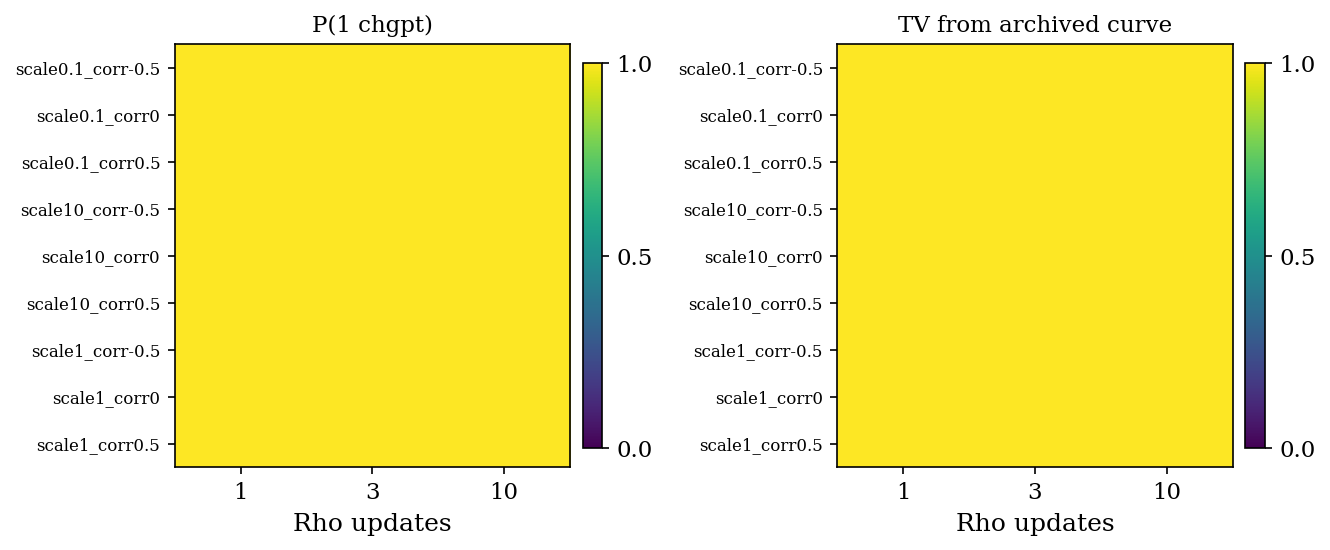

Both logistic fitting budgets = 3


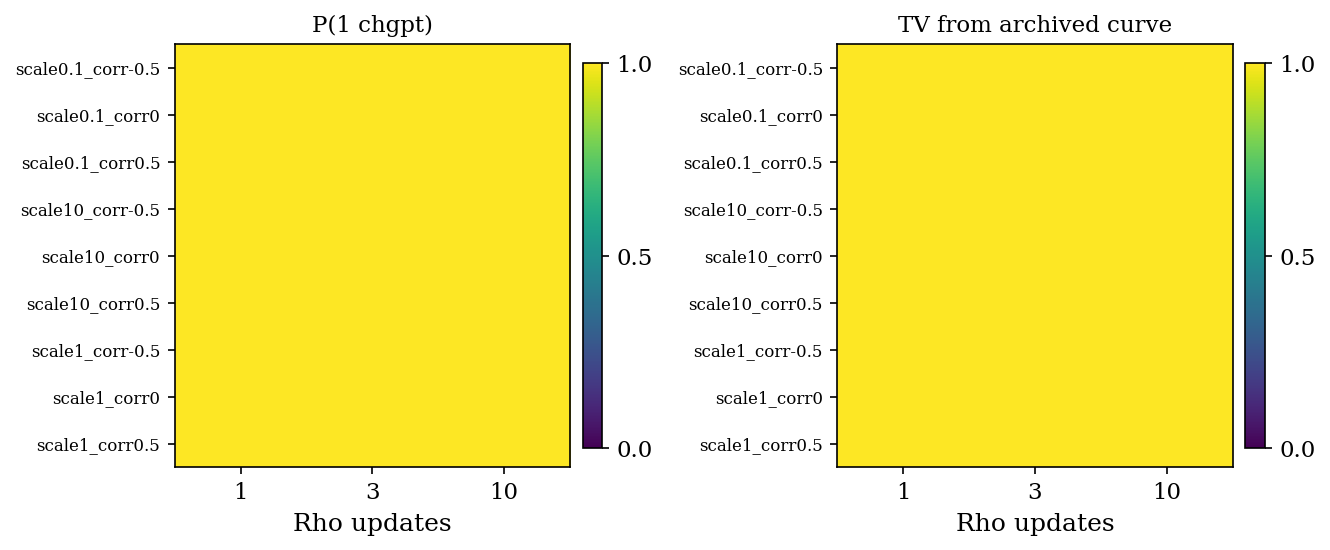

Both logistic fitting budgets = 10


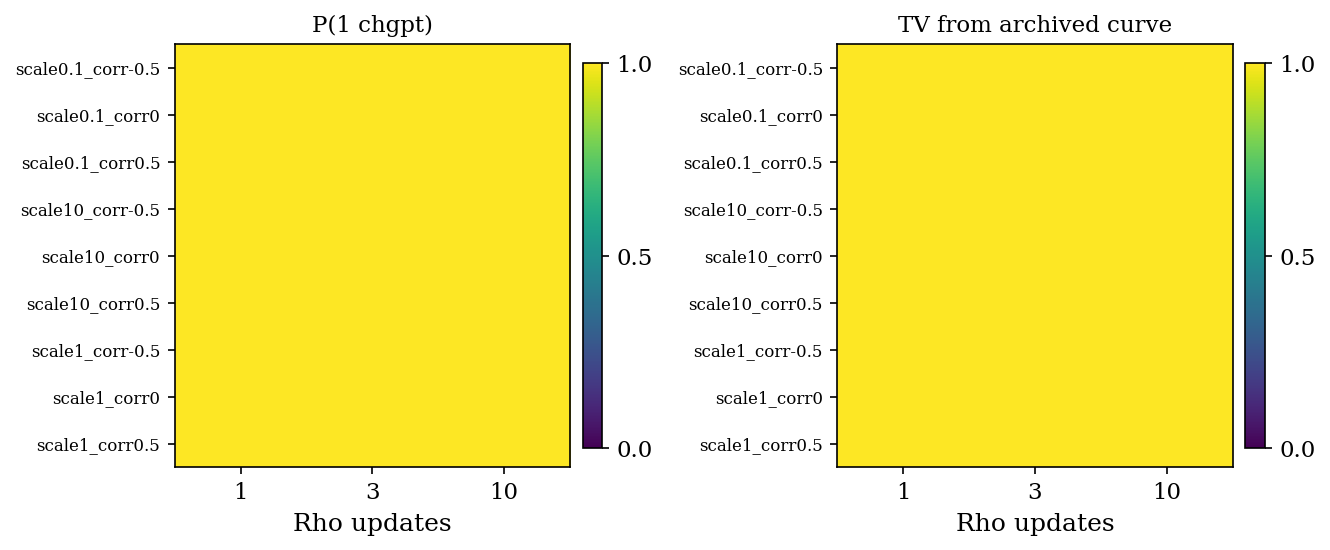

Both logistic fitting budgets = 30


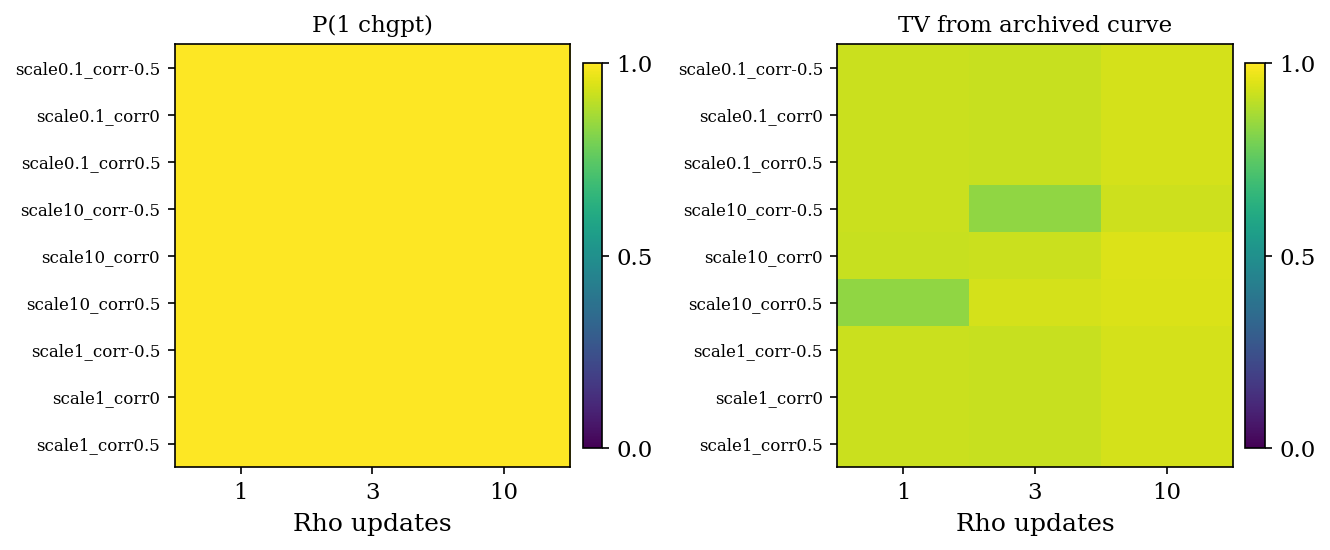

In [11]:
print('All matched-budget settings: initialization sensitivity (primary accuracy)')
matched=summary[summary.group=='logistic_matched']
for budget,data in matched.groupby('auxiliary_budget'):
    print('Both logistic fitting budgets =',budget)
    fig,axes=plt.subplots(1,2,figsize=(9,3.8))
    for ax,key,title in zip(axes,('P_1','TV_to_reference'),('P(1 chgpt)','TV from archived curve')):
        table=data.pivot(index='initialization',columns='rho_updates',values=key)
        im=ax.imshow(table.to_numpy(),vmin=0,vmax=1,aspect='auto',cmap='viridis')
        ax.set_xticks(range(len(table.columns)),table.columns)
        ax.set_yticks(range(len(table.index)),table.index,fontsize=8)
        ax.set_xlabel('Rho updates');ax.set_title(title,fontsize=11)
        fig.colorbar(im,ax=ax,fraction=.045,pad=.03,ticks=(0,.5,1))
    fig.tight_layout();plt.show()


Refined comparisons: all shortlisted settings, including unfavorable numerical checks
scale10_corr0; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8771; moment residual=52.88


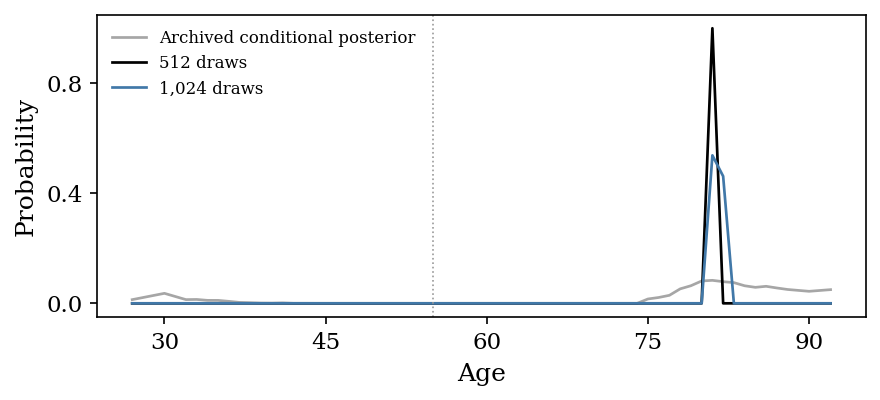

scale1_corr0; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8771; moment residual=53.12


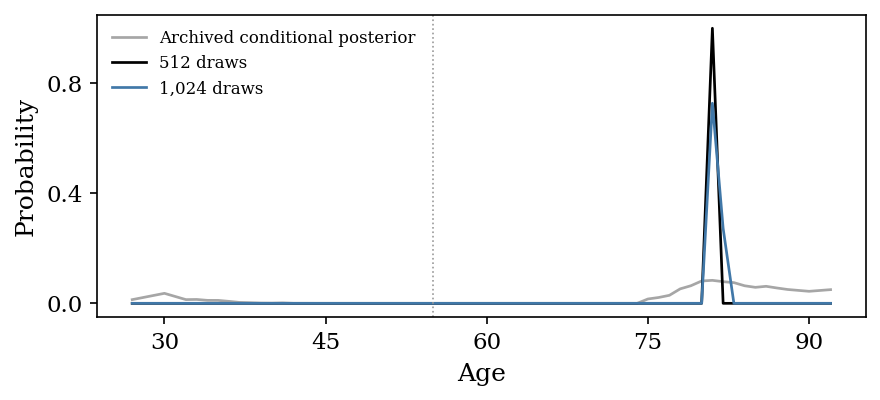

scale1_corr-0.5; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8771; moment residual=53.12


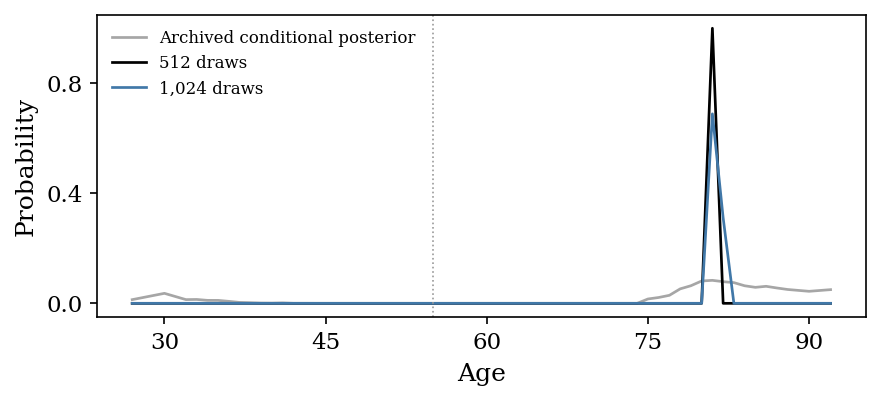

scale0.1_corr0; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.8848; moment residual=53.11


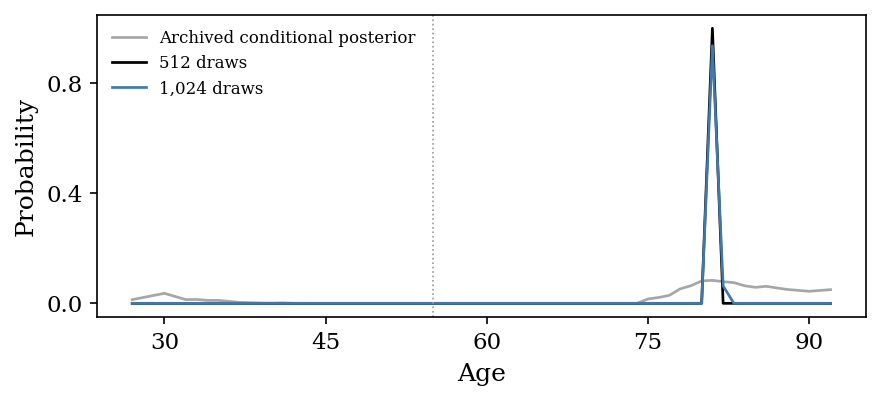

scale10_corr-0.5; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=3
P(1) range 1–1; mean TV=0.9071; moment residual=53.39


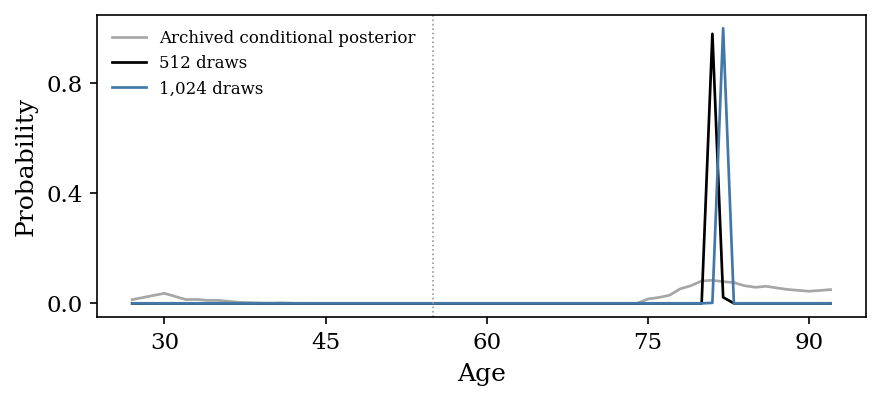

scale0.1_corr0.5; logistic_different_budgets: Delta=1; auxiliary budget=3; posterior budget=100; rho updates=10
P(1) range 1–1; mean TV=0.9176; moment residual=0.08446


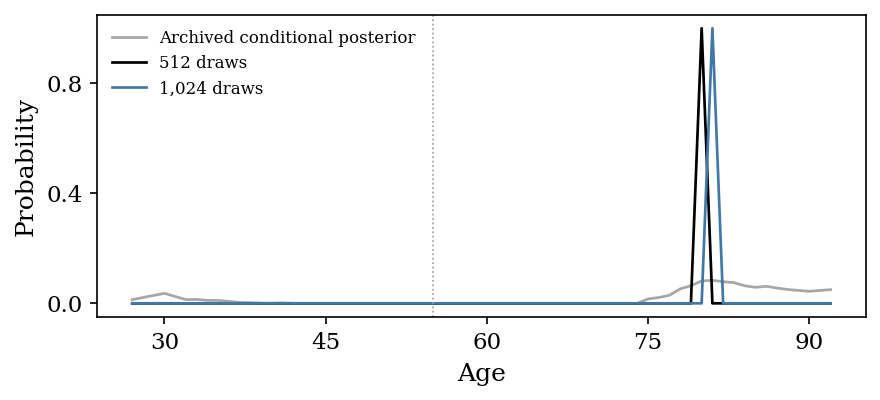

scale10_corr0; logistic_different_budgets: Delta=1; auxiliary budget=1; posterior budget=300; rho updates=10
P(1) range 1–1; mean TV=0.923; moment residual=0.8031


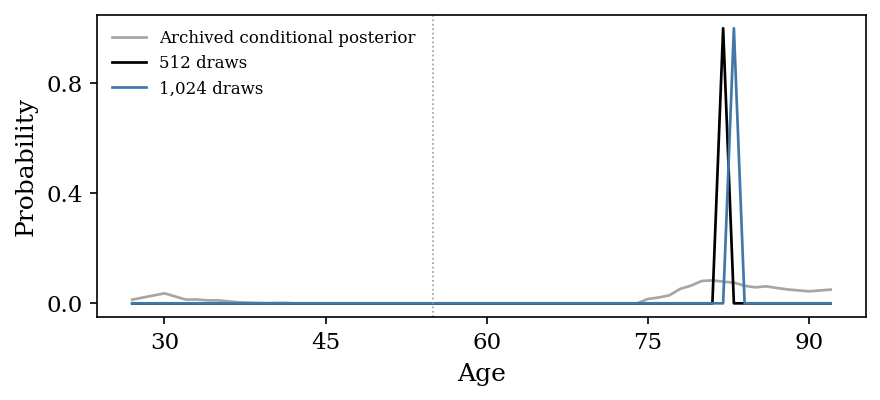

scale10_corr0.5; logistic_matched: Delta=1; auxiliary budget=30; posterior budget=30; rho updates=1
P(1) range 1–1; mean TV=0.9272; moment residual=52.44


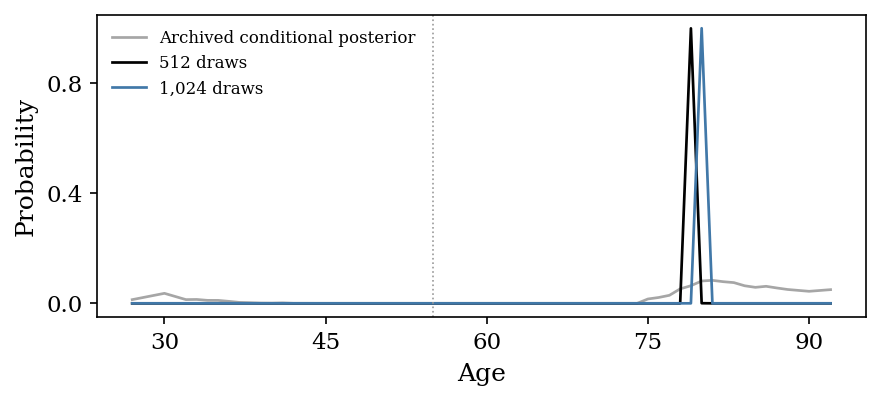

scale0.1_corr-0.5; logistic_different_budgets: Delta=1; auxiliary budget=1; posterior budget=100; rho updates=1
P(1) range 1–1; mean TV=0.9419; moment residual=0.2246


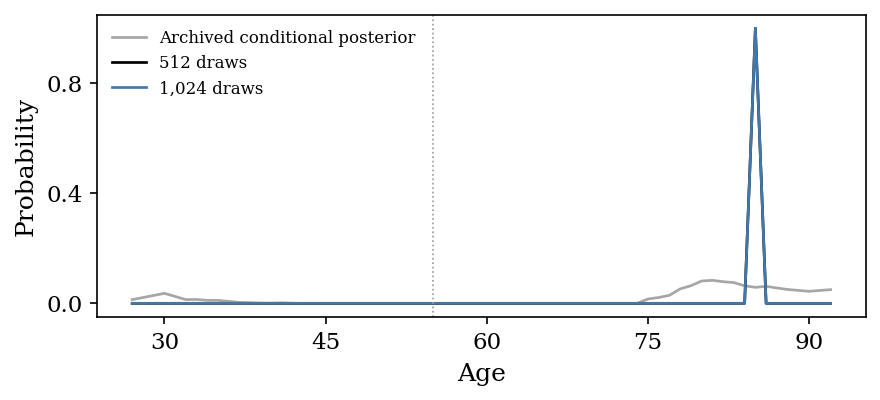

,group,Delta,auxiliary_budget,posterior_budget,rho_updates,tag,P_1,mass_above55,peak_age,interval90_lower,interval90_upper,TV_to_reference,moment_residual,FP_residual_max,fit_kkt_max,coefficient_norm_max
0,logistic_different_budgets,1,1,300,10,q9_seed42,1.0,1.0,82.0,82.0,82.0,0.921291,0.803125,7.284675e-10,0.000002,1172.959608
1,logistic_different_budgets,1,1,300,10,q10_seed123,1.0,1.0,83.0,83.0,83.0,0.924679,0.803125,7.682366e-10,0.000002,1172.959608
2,logistic_different_budgets,1,3,100,10,q9_seed42,1.0,1.0,80.0,80.0,80.0,0.918756,0.084463,7.753005e-10,0.000008,1141.299618
3,logistic_different_budgets,1,3,100,10,q10_seed123,1.0,1.0,81.0,81.0,81.0,0.916440,0.084463,7.462601e-10,0.000008,1141.299618
4,logistic_different_budgets,1,1,100,1,q9_seed42,1.0,1.0,85.0,85.0,85.0,0.941851,0.224598,8.774228e-10,0.000008,1141.299618
5,logistic_different_budgets,1,1,100,1,q10_seed123,1.0,1.0,85.0,85.0,85.0,0.941851,0.224598,9.127722e-10,0.000008,1141.299618
6,logistic_matched,1,30,30,3,q9_seed42,1.0,1.0,81.0,81.0,81.0,0.894532,53.393746,3.662761e-10,0.000152,257.109374
7,logistic_matched,1,30,30,3,q10_seed123,1.0,1.0,82.0,82.0,82.0,0.919658,53.393746,2.781865e-10,0.000152,257.109374
8,logistic_matched,1,30,30,1,q9_seed42,1.0,1.0,79.0,79.0,79.0,0.935615,52.440799,7.462852e-10,0.000152,257.109374
9,logistic_matched,1,30,30,1,q10_seed123,1.0,1.0,80.0,80.0,80.0,0.918756,52.440799,5.959600e-10,0.000152,257.109374


In [12]:
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
print('Refined comparisons: all shortlisted settings, including unfavorable numerical checks')
for row in ranked.itertuples():
    subset=validation[(validation.case==row.case)&(validation.posterior_fit==row.posterior_fit)]
    desc=subset.iloc[0]
    print(f'{row.initialization}; {row.group}: Delta={desc.Delta}; auxiliary budget={desc.auxiliary_budget}; '
          f'posterior budget={desc.posterior_budget}; rho updates={desc.rho_updates}')
    print(f'P(1) range {row.P1_min:.4g}–{row.P1_max:.4g}; mean TV={row.mean_TV:.4g}; '
          f'moment residual={row.moment_residual:.4g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.65',lw=1.3,label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        saved=pickle.load((root/(row.case+'_'+row.posterior_fit+'_'+tag+'.pkl')).open('rb'))
        ax.plot(saved['ages'],saved['conditional'],color=color,lw=1.3,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True));ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
display(validation[['group','Delta','auxiliary_budget','posterior_budget','rho_updates','tag',
                    'P_1','mass_above55','peak_age','interval90_lower','interval90_upper',
                    'TV_to_reference','moment_residual','FP_residual_max','fit_kkt_max','coefficient_norm_max']])


In [13]:
print('Combined finite-iteration shortlist: both sweeps, with numerical sensitivity')
combined=[]
for stage,folder in [('broad',initial_root),('focused',focused_root),('initializations',initialization_root)]:
    table=pd.read_csv(folder/'ranked.csv')
    for row in table.to_dict('records'):
        recs=[pickle.load((folder/(row['case']+'_'+row['posterior_fit']+'_'+tag+'.pkl')).open('rb'))
              for tag in ('q9_seed42','q10_seed123')]
        row.update(stage=stage,Delta=recs[0]['Delta'],auxiliary=recs[0]['auxiliary'],
            auxiliary_budget=recs[0]['auxiliary_budget'],posterior_budget=recs[0]['posterior_budget'],
            rho_updates=recs[0]['rho_updates'],
            numerical_curve_TV=.5*np.abs(recs[0]['conditional']-recs[1]['conditional']).sum(),
            min_interval90_width=min(r['interval90_upper']-r['interval90_lower'] for r in recs),
            max_interval90_width=max(r['interval90_upper']-r['interval90_lower'] for r in recs))
        combined.append(row)
combined=pd.DataFrame(combined).sort_values('mean_TV')
combined.to_csv(initial_root/'combined_checked_candidates.csv',index=False)
display(combined)
print('These are exploratory comparisons, not independently validated model choices.')


Combined finite-iteration shortlist: both sweeps, with numerical sensitivity


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,...,stage,Delta,auxiliary,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width,initialization
13,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,...,focused,5,least_squares,0,16,24,3.130377e-02,54.0,54.0,NaN
14,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,...,focused,2,least_squares,0,12,20,2.424608e-02,16.0,57.0,NaN
15,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,...,focused,2,least_squares,0,16,20,3.062949e-02,10.0,13.0,NaN
16,d5_least_squares_it20_q8_b60,lbfgs5,least_squares,0.205679,0.214709,0.248653,0.248909,9.009691e-01,84.0,84.0,...,focused,5,least_squares,0,5,20,6.232307e-02,11.0,55.0,NaN
17,d10_least_squares_it20_q8_b60,lbfgs5,least_squares,0.201833,0.205649,0.266246,0.270968,9.476632e-01,83.0,83.0,...,focused,10,least_squares,0,5,20,3.427498e-02,10.0,50.0,NaN
18,d2_least_squares_it16_q8_b60,lbfgs5,least_squares,0.305700,0.316399,0.305304,0.321317,9.217486e-01,84.0,84.0,...,focused,2,least_squares,0,5,16,6.591722e-02,10.0,58.0,NaN
0,d1_least_squares_it30_q8_b60,early10,least_squares,0.401266,0.406337,0.494824,0.499693,6.327934e-01,27.0,78.0,...,broad,1,least_squares,0,10,30,1.873924e-02,58.0,58.0,NaN
1,d1_least_squares_it30_q8_b60,early3,least_squares,0.489498,0.495491,0.618732,0.622118,6.159525e-01,72.0,72.0,...,broad,1,least_squares,0,3,30,1.101070e-02,56.0,56.0,NaN
2,d1_least_squares_it30_q8_b60,early1,least_squares,0.511236,0.518780,0.639888,0.642866,6.193926e-01,69.0,69.0,...,broad,1,least_squares,0,1,30,8.183063e-03,54.0,54.0,NaN
28,d1_early30_init_scale10_corr0_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877078,0.916425,1.000000e+00,81.0,81.0,...,initializations,1,early30_init_scale10_corr0,30,30,3,4.620850e-01,0.0,1.0,scale10_corr0


These are exploratory comparisons, not independently validated model choices.


## Queued follow-up: fine matched-L2 full solves

# Fine matched-L2 sweep: fully solved logistic fits

Both auxiliary and posterior-input fits minimize the **same** weighted mean logistic
loss plus $\lambda\|\beta\|_2^2$, with the **same strength**, no intercept, and the
same coefficient solution reused in both stages. This is separate from early stopping.
The 35 strengths are eight per decade from $10^{-8}$ to $10^{-4}$, plus
$3\times10^{-4}$ and $10^{-3}$. Coefficients are solved by damped Newton until the
maximum gradient magnitude is at most $10^{-10}$ and the strong-convexity
objective-gap bound $\|\nabla f\|^2/(4\lambda)$ is at most $10^{-8}$.
Failure to meet these criteria raises an error; a finite safety budget is not treated
as a converged fit. The solver was tested against an independent BFGS solution.

All other choices are explicit and unchanged: centered/whitened 110 predictors,
1,692 observations, no intercept, $\Delta=1$, equal prior odds for zero/one change,
uniform location over the 61 admissible distinct-age splits, rho start $I_2$,
damping 0.25, and 1, 3, 10, 30 rho updates. This makes **140 primary comparisons**.
State calculations initially use 256 Sobol draws/seed 42 and at most 60 evaluations.
The four closest curves and two highest-count-probability curves within 0.10 TV of
the best are checked with 512 draws/seed 42 and 1,024 draws/seed 123, at most 100
state evaluations, and 160-node Gaussian quadrature. No P(1)>0.5 cutoff is imposed.

**Full solve refers only to coefficient optimization.** Rho estimation remains a
finite-update heuristic, and the existing approximately unpenalized state equations
are used with the weakly penalized fits. Those approximation/model limitations are
not removed by accurate coefficient solves. Outcome-guided comparison with the
archived curve remains exploratory, not independently calibrated model selection.


In [1]:
"""Fine matched-L2 full coefficient solves; separate from early stopping."""
from tools.myocardial_finite_iteration_exploration import *
from tools.myocardial_exact_no_intercept import score as matched_score


def penalty_grid():
    return np.r_[np.logspace(-8,-4,33),3e-4,1e-3]


def solve_logistic_l2(X,y,w,strength):
    """Damped Newton to stationarity, not a chosen finite fitting budget.

    Objective = weighted mean logistic loss + strength * ||beta||^2.
    The strong-convexity gap bound ||gradient||^2/(4*strength) is recorded.
    A safety limit raises an error rather than returning an early-stopped fit.
    """
    if not np.isfinite(strength) or strength<=0:raise ValueError('positive finite L2 strength required')
    X=np.asarray(X,float);y=np.asarray(y,float);w=np.asarray(w,float)
    if not np.isfinite(w).all() or np.any(w<0) or w.sum()<=0:raise ValueError('invalid sample weights')
    wn=w/w.sum();beta=np.zeros(X.shape[1]);eye=np.eye(X.shape[1])
    def value(b):
        z=X@b
        return float(wn@(np.logaddexp(0,z)-y*z)+strength*(b@b))
    for it in range(101):
        z=X@beta;prob=expit(z);grad=X.T@(wn*(prob-y))+2*strength*beta
        kkt=float(np.max(abs(grad)));gap=float(grad@grad/(4*strength))
        if kkt<=1e-10 and gap<=1e-8:
            return dict(coef=beta,kkt=kkt,gap_bound=gap,iterations=it,objective=value(beta),success=True)
        if it==100:break
        H=X.T@((wn*prob*(1-prob))[:,None]*X)+2*strength*eye
        direction=np.linalg.solve(H,grad);decrease=float(grad@direction);old=value(beta);step=1.
        for backtrack in range(60):
            candidate=beta-step*direction
            if value(candidate)<=old-1e-4*step*decrease+1e-15:
                beta=candidate;break
            step*=.5
        else:raise RuntimeError('Full L2 solve line search failed')
    raise RuntimeError(f'Full L2 solve failed stationarity: KKT={kkt}, gap={gap}')


def full_fit(X,y,phi,strength):
    fits=[solve_logistic_l2(X,y,w,strength) for w in phi]
    B=np.column_stack([f['coef'] for f in fits]);theta=X@B
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    return dict(coef=B,theta=theta,V=V,b=b,penalty='l2',strength=float(strength),
        checks=[{k:v for k,v in f.items() if k!='coef'} for f in fits])


def prepare_full(strength,setting,X,y,root):
    name=f'l2full_{strength:.12g}';path=root/('aux_'+name+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    fit=full_fit(X,y,setting['phi'],strength)
    e,psi=pilot(fit['theta'],y,setting['eta'],'logistic');S=fit['V'].T@fit['V']/len(y)
    import WERM.myocardial_approximate as implementation
    old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
    try:
        scenarios=[dict(r,auxiliary=name,pilot=e,loss='logistic')
            for r in rho_path(S,setting['phi'],psi,len(y)/X.shape[1],'logistic')]
    finally:implementation.logistic_prox=old
    result=(name,fit,scenarios);atomic_save(path,result)
    print('Full matched L2 fit and rho path ready:',strength,flush=True);return result


def score_full(rec,states,fit,setting,X,y,ages,reference,root,tag):
    path=root/(rec['label']+'_'+tag+'_score.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    result=matched_score(rec,states,fit,setting,X,y,ages,reference,tag)
    result.update(label=rec['label']+'_'+tag,tag=tag,ages=ages[setting['eta'][1:]],
        posterior_fit=rec['scenario']['auxiliary'],group='fully_solved_matched_L2',
        Delta=1,rho_updates=rec['scenario']['iteration'],auxiliary=rec['scenario']['auxiliary'],
        auxiliary_strength=fit['strength'],posterior_strength=fit['strength'],
        gap_bound_max=max(c['gap_bound'] for c in fit['checks']),
        actual_fit_iterations_max=max(c['iterations'] for c in fit['checks']))
    atomic_save(path,result);return result


def run_full_matched(base):
    X,y,ages,locations=load_data();reference_map=reference_distribution()
    reference=np.array([reference_map[a] for a in ages[locations]])
    setting=pickle.load((SOURCE/'fits_delta1.pkl').open('rb'))
    digest=hashlib.sha256(Path('tools/myocardial_matched_l2_fine.py').read_bytes()).hexdigest()[:12]
    root=base/('matched_l2_full_'+digest);root.mkdir(exist_ok=True)
    print('Fine full-solve matched L2 directory:',root,flush=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=35)(delayed(prepare_full)(v,setting,X,y,root) for v in penalty_grid())
        tasks=[(name,fit,r) for name,fit,scenarios in prepared for r in scenarios]
        records=Parallel(n_jobs=36)(delayed(evaluate_refined)(dict(setting,fits={}),r,X,y,ages,root,8,60) for name,fit,r in tasks)
        results=Parallel(n_jobs=36)(delayed(score_full)(rec,rec['states'],fit,setting,X,y,ages,reference,root,'primary')
                                    for rec,(name,fit,r) in zip(records,tasks))
    def table(rows):return pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages')} for r in rows])
    summary=table(results);summary.to_csv(root/'summary.csv',index=False)
    # Shape first, with count probability a trade-off, never a hard filter.
    closest=summary.sort_values('TV_to_reference').head(4)
    nearby=summary[summary.TV_to_reference<=summary.TV_to_reference.min()+.1].sort_values('P_1',ascending=False).head(2)
    selected=pd.concat([closest,nearby]).drop_duplicates('case')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    case_map={r['label']:(r,t[1]) for r,t in zip(records,tasks)}
    jobs=[(case_map[c],power,seed) for c in selected.case for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        states=Parallel(n_jobs=len(jobs))(delayed(refined_states)(r,setting,len(y),X.shape[1],root,power,seed)
                                        for (r,fit),power,seed in jobs)
        checks=Parallel(n_jobs=36)(delayed(score_full)(r,state,fit,setting,X,y,ages,reference,root,f'q{power}_seed{seed}')
                                  for ((r,fit),power,seed),state in zip(jobs,states))
    validation=table(checks);validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby(['case','posterior_fit','group','strength'],as_index=False).agg(
        P1_min=('P_1','min'),P1_max=('P_1','max'),mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
        mass_above55_min=('mass_above55','min'),peak_min=('peak_age','min'),peak_max=('peak_age','max'),
        moment_residual=('moment_residual','max'),fit_kkt_max=('fit_kkt_max','max'),gap_bound_max=('gap_bound_max','max')).sort_values('mean_TV')
    ranked.to_csv(root/'ranked.csv',index=False)
    print('FULL-SOLVE MATCHED L2 COMPLETE:',len(summary),'primary comparisons.',flush=True)
    print(ranked.to_string(index=False),flush=True);return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base=Path('results/myocardial_finite_iteration_443c17cf2df6')
matched_root=run_full_matched(base)
full_summary=pd.read_csv(matched_root/'summary.csv')
full_validation=pd.read_csv(matched_root/'validation.csv')
full_ranked=pd.read_csv(matched_root/'ranked.csv')
display(full_ranked)


Fine full-solve matched L2 directory: results/myocardial_finite_iteration_443c17cf2df6/matched_l2_full_affdef22fb6c


Full matched L2 fit and rho path ready: 4.216965034285822e-05


Full matched L2 fit and rho path ready: 7.498942093324559e-05


Full matched L2 fit and rho path ready: 2.3713737056616554e-05


Full matched L2 fit and rho path ready: 9.999999999999999e-06


Full matched L2 fit and rho path ready: 3.1622776601683795e-05


... (165 outputs left out)

Numerical validation complete: d1_l2full_7.49894209332e-05_it30_q8_b60 10 123


FULL-SOLVE MATCHED L2 COMPLETE: 140 primary comparisons.


                                   case            posterior_fit                   group  strength   P1_min   P1_max  mean_TV   max_TV  mass_above55_min  peak_min  peak_max  moment_residual  fit_kkt_max  gap_bound_max
d1_l2full_4.21696503429e-05_it30_q8_b60 l2full_4.21696503429e-05 fully_solved_matched_L2  0.000042 0.511128 0.520916 0.648567 0.652651          0.596253      66.0      68.0         0.284075 2.259364e-12   1.511175e-19
 d1_l2full_5.6234132519e-05_it30_q8_b60  l2full_5.6234132519e-05 fully_solved_matched_L2  0.000056 0.512744 0.524969 0.651158 0.656271          0.594404      66.0      67.0         0.367151 3.468395e-14   2.686072e-23
d1_l2full_7.49894209332e-05_it30_q8_b60 l2full_7.49894209332e-05 fully_solved_matched_L2  0.000075 0.513934 0.528315 0.653160 0.659173          0.592811      66.0      66.0         0.437351 2.573896e-16   1.109694e-27
           d1_l2full_0.0001_it30_q8_b60            l2full_0.0001 fully_solved_matched_L2  0.000100 0.514800 0.530982 0.654661 0.

,case,posterior_fit,group,strength,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual,fit_kkt_max,gap_bound_max
0,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.000042,0.511128,0.520916,0.648567,0.652651,0.596253,66.0,68.0,0.284075,2.259364e-12,1.511175e-19
1,d1_l2full_5.6234132519e-05_it30_q8_b60,l2full_5.6234132519e-05,fully_solved_matched_L2,0.000056,0.512744,0.524969,0.651158,0.656271,0.594404,66.0,67.0,0.367151,3.468395e-14,2.686072e-23
2,d1_l2full_7.49894209332e-05_it30_q8_b60,l2full_7.49894209332e-05,fully_solved_matched_L2,0.000075,0.513934,0.528315,0.653160,0.659173,0.592811,66.0,66.0,0.437351,2.573896e-16,1.109694e-27
3,d1_l2full_0.0001_it30_q8_b60,l2full_0.0001,fully_solved_matched_L2,0.000100,0.514800,0.530982,0.654661,0.661420,0.591512,65.0,66.0,0.493835,3.281310e-11,1.331241e-17
4,d1_l2full_0.0003_it30_q8_b60,l2full_0.0003,fully_solved_matched_L2,0.000300,0.516320,0.536090,0.657259,0.665487,0.588921,64.0,66.0,0.600446,3.355606e-17,4.769203e-30
5,d1_l2full_0.001_it30_q8_b60,l2full_0.001,fully_solved_matched_L2,0.001000,0.516698,0.537052,0.657694,0.666157,0.588282,64.0,66.0,0.616852,7.511060e-14,7.034816e-24


All matched strengths: primary numerical accuracy


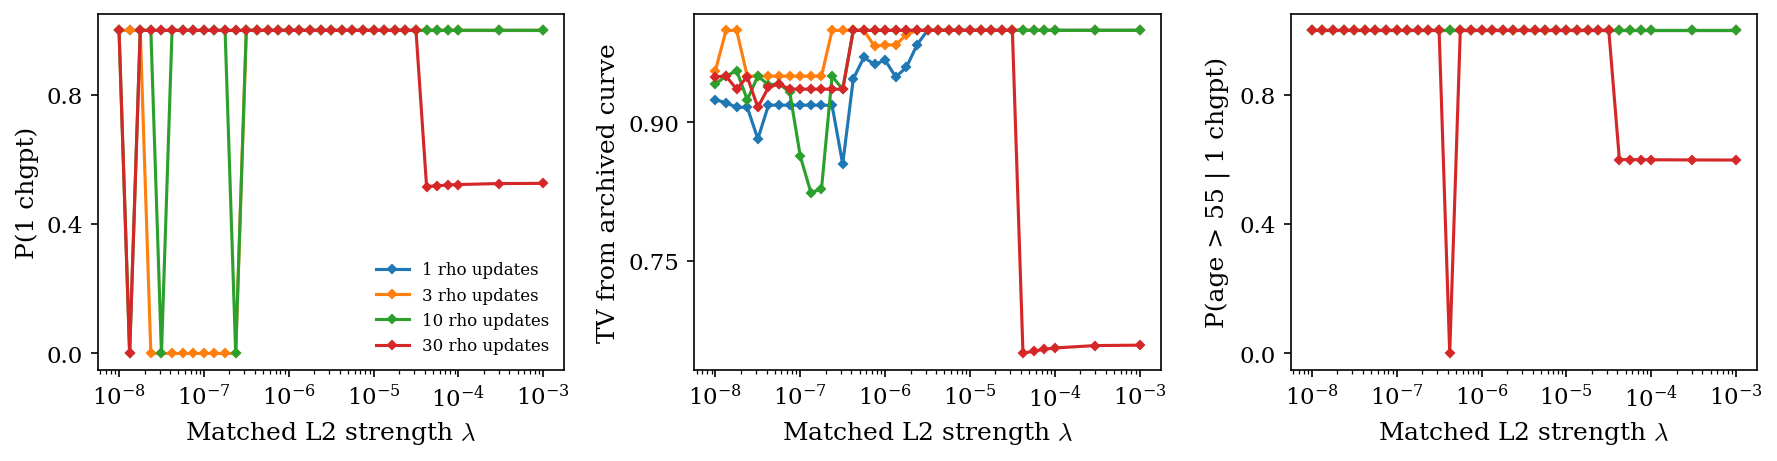

Both stages: L2=4.21697e-05; d1_l2full_4.21696503429e-05_it30_q8_b60; P(1)=0.5111–0.5209; mean TV=0.6486


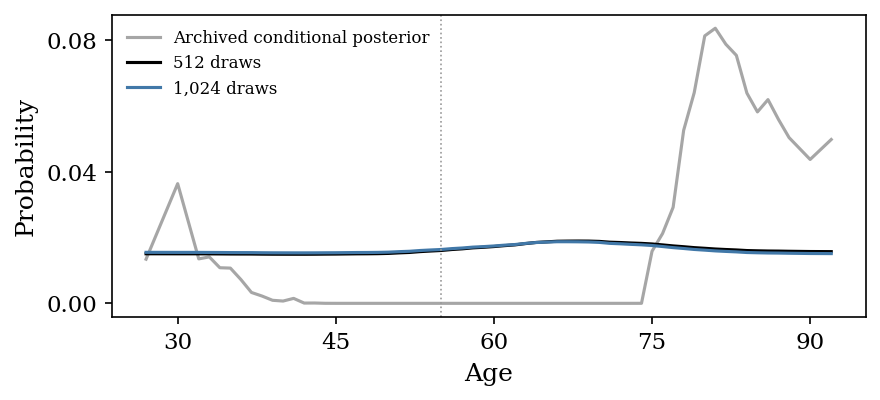

Both stages: L2=5.62341e-05; d1_l2full_5.6234132519e-05_it30_q8_b60; P(1)=0.5127–0.525; mean TV=0.6512


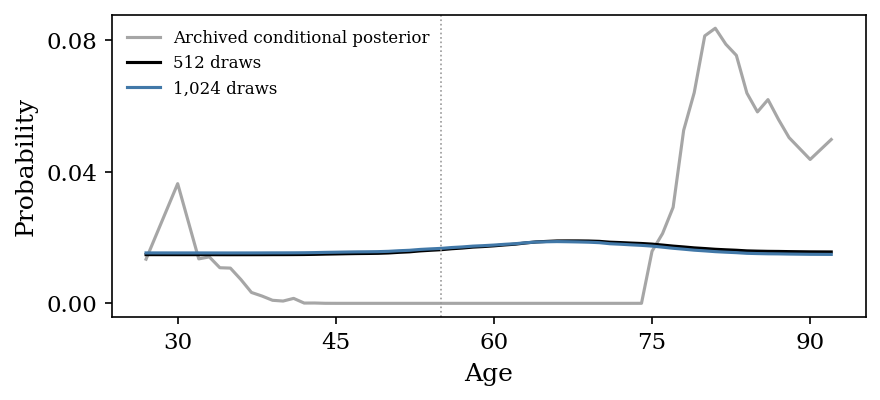

Both stages: L2=7.49894e-05; d1_l2full_7.49894209332e-05_it30_q8_b60; P(1)=0.5139–0.5283; mean TV=0.6532


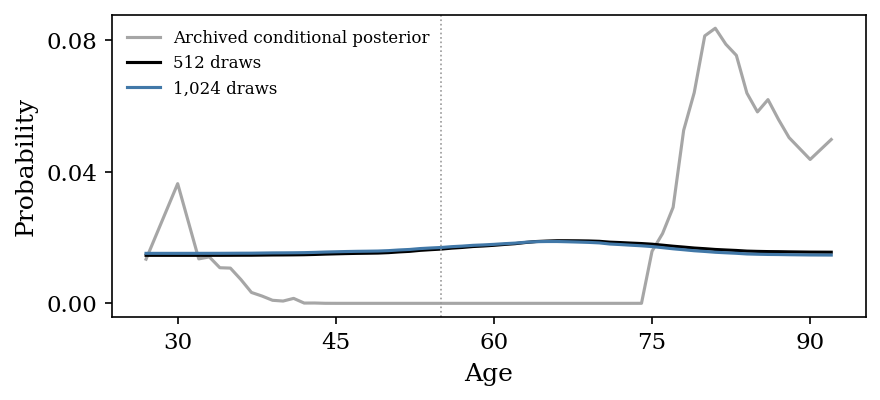

Both stages: L2=0.0001; d1_l2full_0.0001_it30_q8_b60; P(1)=0.5148–0.531; mean TV=0.6547


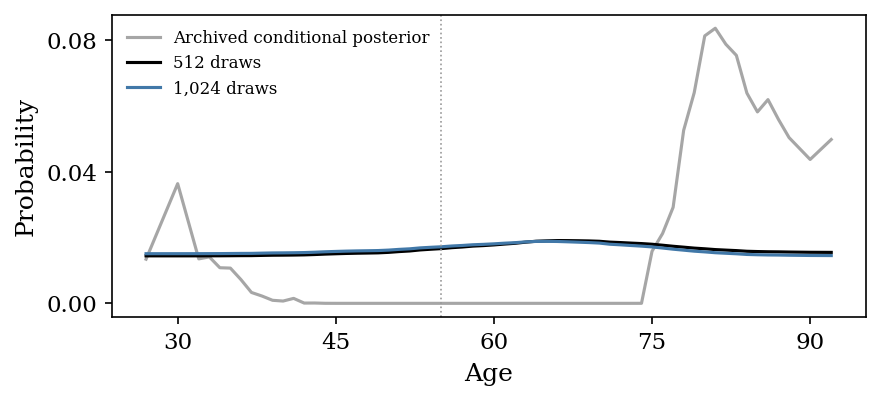

Both stages: L2=0.0003; d1_l2full_0.0003_it30_q8_b60; P(1)=0.5163–0.5361; mean TV=0.6573


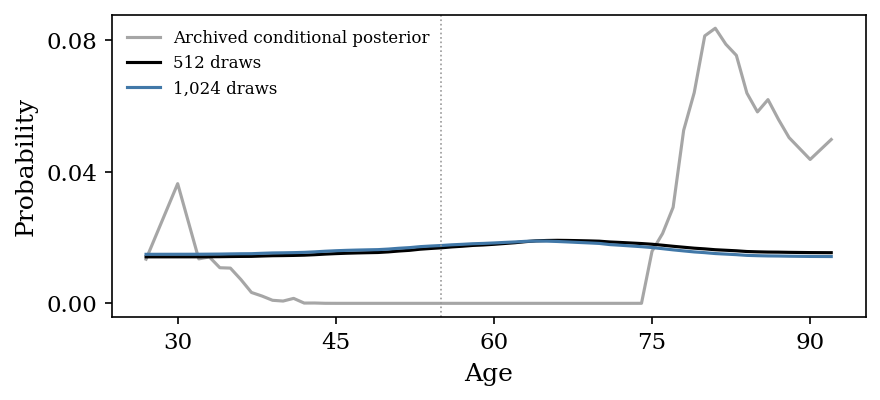

Both stages: L2=0.001; d1_l2full_0.001_it30_q8_b60; P(1)=0.5167–0.5371; mean TV=0.6577


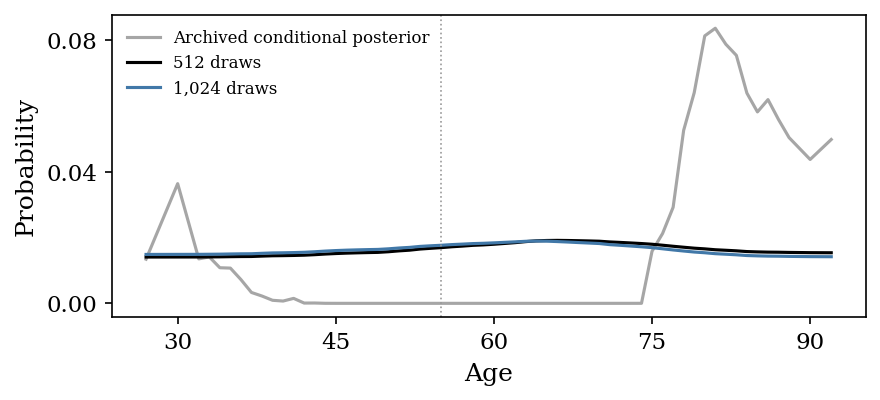

,case,penalty,strength,seed_label,P_1,mass_above55,peak_age,TV_to_reference,moment_residual,FP_residual_max,...,tag,posterior_fit,group,Delta,rho_updates,auxiliary,auxiliary_strength,posterior_strength,gap_bound_max,actual_fit_iterations_max
0,d1_l2full_4.21696503429e-05_it30_q8_b60,l2,0.000042,q9_seed42,0.511128,0.606726,68.0,0.644483,0.284075,1.147679e-09,...,q9_seed42,l2full_4.21696503429e-05,fully_solved_matched_L2,1,30,l2full_4.21696503429e-05,0.000042,0.000042,1.511175e-19,4
1,d1_l2full_4.21696503429e-05_it30_q8_b60,l2,0.000042,q10_seed123,0.520916,0.596253,66.0,0.652651,0.284075,1.188796e-09,...,q10_seed123,l2full_4.21696503429e-05,fully_solved_matched_L2,1,30,l2full_4.21696503429e-05,0.000042,0.000042,1.511175e-19,4
2,d1_l2full_5.6234132519e-05_it30_q8_b60,l2,0.000056,q9_seed42,0.512744,0.607587,67.0,0.646044,0.367151,1.147679e-09,...,q9_seed42,l2full_5.6234132519e-05,fully_solved_matched_L2,1,30,l2full_5.6234132519e-05,0.000056,0.000056,2.686072e-23,4
3,d1_l2full_5.6234132519e-05_it30_q8_b60,l2,0.000056,q10_seed123,0.524969,0.594404,66.0,0.656271,0.367151,1.188796e-09,...,q10_seed123,l2full_5.6234132519e-05,fully_solved_matched_L2,1,30,l2full_5.6234132519e-05,0.000056,0.000056,2.686072e-23,4
4,d1_l2full_7.49894209332e-05_it30_q8_b60,l2,0.000075,q9_seed42,0.513934,0.608361,66.0,0.647146,0.437351,1.147679e-09,...,q9_seed42,l2full_7.49894209332e-05,fully_solved_matched_L2,1,30,l2full_7.49894209332e-05,0.000075,0.000075,1.109694e-27,4
5,d1_l2full_7.49894209332e-05_it30_q8_b60,l2,0.000075,q10_seed123,0.528315,0.592811,66.0,0.659173,0.437351,1.188796e-09,...,q10_seed123,l2full_7.49894209332e-05,fully_solved_matched_L2,1,30,l2full_7.49894209332e-05,0.000075,0.000075,1.109694e-27,4
6,d1_l2full_0.0001_it30_q8_b60,l2,0.000100,q9_seed42,0.514800,0.609021,66.0,0.647903,0.493835,1.147679e-09,...,q9_seed42,l2full_0.0001,fully_solved_matched_L2,1,30,l2full_0.0001,0.000100,0.000100,1.331241e-17,3
7,d1_l2full_0.0001_it30_q8_b60,l2,0.000100,q10_seed123,0.530982,0.591512,65.0,0.661420,0.493835,1.188796e-09,...,q10_seed123,l2full_0.0001,fully_solved_matched_L2,1,30,l2full_0.0001,0.000100,0.000100,1.331241e-17,3
8,d1_l2full_0.001_it30_q8_b60,l2,0.001000,q9_seed42,0.516698,0.610275,66.0,0.649232,0.616852,1.147679e-09,...,q9_seed42,l2full_0.001,fully_solved_matched_L2,1,30,l2full_0.001,0.001000,0.001000,7.034816e-24,2
9,d1_l2full_0.001_it30_q8_b60,l2,0.001000,q10_seed123,0.537052,0.588282,64.0,0.666157,0.616852,1.188796e-09,...,q10_seed123,l2full_0.001,fully_solved_matched_L2,1,30,l2full_0.001,0.001000,0.001000,7.034816e-24,2


In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
                     'axes.labelsize':12,'figure.dpi':150})
print('All matched strengths: primary numerical accuracy')
fig,axes=plt.subplots(1,3,figsize=(12,3.2))
for updates,data in full_summary.groupby('rho_updates'):
    data=data.sort_values('strength')
    for ax,key in zip(axes,('P_1','TV_to_reference','mass_above55')):
        ax.semilogx(data.strength,data[key],'-D',ms=3,label=f'{updates} rho updates')
for ax,label in zip(axes,('P(1 chgpt)','TV from archived curve','P(age > 55 | 1 chgpt)')):
    ax.set_xlabel(r'Matched L2 strength $\lambda$');ax.set_ylabel(label)
    ax.yaxis.set_major_locator(MaxNLocator(3))
axes[0].legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
for row in full_ranked.itertuples():
    print(f'Both stages: L2={row.strength:g}; {row.case}; '
          f'P(1)={row.P1_min:.4g}–{row.P1_max:.4g}; mean TV={row.mean_TV:.4g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.65',label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        rec=pickle.load((matched_root/(row.case+'_'+tag+'_score.pkl')).open('rb'))
        ax.plot(rec['ages'],rec['conditional'],color=color,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.yaxis.set_major_locator(MaxNLocator(3));ax.xaxis.set_major_locator(MaxNLocator(5,integer=True))
    ax.legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
display(full_validation)


In [4]:
print('Combined numerically checked candidates: early stopping, initializations, and full matched L2')
earlier=pd.read_csv(base/'combined_checked_candidates.csv')
new=[]
for row in full_ranked.to_dict('records'):
    recs=[pickle.load((matched_root/(row['case']+'_'+tag+'_score.pkl')).open('rb'))
          for tag in ('q9_seed42','q10_seed123')]
    row.update(stage='fully_solved_matched_L2',Delta=1,initialization='identity',
        auxiliary=recs[0]['auxiliary'],rho_updates=recs[0]['rho_updates'],
        numerical_curve_TV=.5*np.abs(recs[0]['conditional']-recs[1]['conditional']).sum())
    new.append(row)
all_candidates=pd.concat([earlier,pd.DataFrame(new)],ignore_index=True).sort_values('mean_TV')
all_candidates.to_csv(base/'combined_with_full_l2.csv',index=False)
display(all_candidates)
print('Best curve matches in each class (not a statistical acceptance rule):')
display(all_candidates.groupby('group',sort=False).head(3))
print('Ranges across numerical checks are not confidence intervals. Small TV does not establish calibration.')


Combined numerically checked candidates: early stopping, initializations, and full matched L2


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,...,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width,initialization,strength,fit_kkt_max,gap_bound_max
0,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,...,0.0,16.0,24,3.130377e-02,54.0,54.0,NaN,NaN,NaN,NaN
1,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,...,0.0,12.0,20,2.424608e-02,16.0,57.0,NaN,NaN,NaN,NaN
2,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,...,0.0,16.0,20,3.062949e-02,10.0,13.0,NaN,NaN,NaN,NaN
3,d5_least_squares_it20_q8_b60,lbfgs5,least_squares,0.205679,0.214709,0.248653,0.248909,9.009691e-01,84.0,84.0,...,0.0,5.0,20,6.232307e-02,11.0,55.0,NaN,NaN,NaN,NaN
4,d10_least_squares_it20_q8_b60,lbfgs5,least_squares,0.201833,0.205649,0.266246,0.270968,9.476632e-01,83.0,83.0,...,0.0,5.0,20,3.427498e-02,10.0,50.0,NaN,NaN,NaN,NaN
5,d2_least_squares_it16_q8_b60,lbfgs5,least_squares,0.305700,0.316399,0.305304,0.321317,9.217486e-01,84.0,84.0,...,0.0,5.0,16,6.591722e-02,10.0,58.0,NaN,NaN,NaN,NaN
6,d1_least_squares_it30_q8_b60,early10,least_squares,0.401266,0.406337,0.494824,0.499693,6.327934e-01,27.0,78.0,...,0.0,10.0,30,1.873924e-02,58.0,58.0,NaN,NaN,NaN,NaN
7,d1_least_squares_it30_q8_b60,early3,least_squares,0.489498,0.495491,0.618732,0.622118,6.159525e-01,72.0,72.0,...,0.0,3.0,30,1.101070e-02,56.0,56.0,NaN,NaN,NaN,NaN
8,d1_least_squares_it30_q8_b60,early1,least_squares,0.511236,0.518780,0.639888,0.642866,6.193926e-01,69.0,69.0,...,0.0,1.0,30,8.183063e-03,54.0,54.0,NaN,NaN,NaN,NaN
37,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.511128,0.520916,0.648567,0.652651,5.962531e-01,66.0,68.0,...,NaN,NaN,30,1.192095e-02,NaN,NaN,identity,0.000042,2.259364e-12,1.511175e-19


Best curve matches in each class (not a statistical acceptance rule):


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,...,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width,initialization,strength,fit_kkt_max,gap_bound_max
0,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,...,0.0,16.0,24,3.130377e-02,54.0,54.0,NaN,NaN,NaN,NaN
1,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,...,0.0,12.0,20,2.424608e-02,16.0,57.0,NaN,NaN,NaN,NaN
2,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,...,0.0,16.0,20,3.062949e-02,10.0,13.0,NaN,NaN,NaN,NaN
37,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.511128,0.520916,0.648567,0.652651,5.962531e-01,66.0,68.0,...,NaN,NaN,30,1.192095e-02,NaN,NaN,identity,0.000042,2.259364e-12,1.511175e-19
38,d1_l2full_5.6234132519e-05_it30_q8_b60,l2full_5.6234132519e-05,fully_solved_matched_L2,0.512744,0.524969,0.651158,0.656271,5.944039e-01,66.0,67.0,...,NaN,NaN,30,1.507890e-02,NaN,NaN,identity,0.000056,3.468395e-14,2.686072e-23
39,d1_l2full_7.49894209332e-05_it30_q8_b60,l2full_7.49894209332e-05,fully_solved_matched_L2,0.513934,0.528315,0.653160,0.659173,5.928107e-01,66.0,66.0,...,NaN,NaN,30,1.784189e-02,NaN,NaN,identity,0.000075,2.573896e-16,1.109694e-27
9,d1_early30_init_scale10_corr0_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877078,0.916425,1.000000e+00,81.0,81.0,...,30.0,30.0,3,4.620850e-01,0.0,1.0,scale10_corr0,NaN,NaN,NaN
10,d1_early30_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,...,30.0,30.0,3,2.725689e-01,0.0,1.0,NaN,NaN,NaN,NaN
11,d1_early30_init_scale1_corr0_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,...,30.0,30.0,3,2.725689e-01,0.0,1.0,scale1_corr0,NaN,NaN,NaN
14,d1_early100_it30_q8_b60,early1,logistic_different_budgets,1.000000,1.000000,0.885094,0.885094,1.330201e-71,35.0,41.0,...,100.0,1.0,30,3.918490e-02,12.0,12.0,NaN,NaN,NaN,NaN


Ranges across numerical checks are not confidence intervals. Small TV does not establish calibration.


## Earlier promising alternatives (retained in the final comparison)

| Earlier fit setup | Intercept | P(1) across numerical checks | Main trade-off |
|---|---|---|---|
| LS auxiliary; logistic L1 1e-4 posterior fit; 30 rho updates | No | 0.402–0.453 | Mode 79; original-like but count probability below 0.5 |
| LS auxiliary; logistic L2 1e-6 posterior fit; 3 rho updates | No | 0.99988–0.99998 | Mode 87; too concentrated/late relative to reference |
| LS auxiliary; logistic L2 1e-5 posterior fit; 30 rho updates | No | 0.481–0.484 | Mode 75; diffuse |
| Logistic L1 1e-4 auxiliary; logistic L2 1.5e-6 posterior fit; 30 updates | Yes | 0.718–0.747 | Mode 81; mean reference TV 0.291; mismatched penalties |
| Logistic L1 1e-4 auxiliary; logistic L1 1e-5 posterior fit; 30 updates | Yes | 0.654–0.680 | Mode 81; mean reference TV 0.367; mismatched strengths |

These historical candidates remain exploratory and are not relabeled as satisfying
the no-intercept or exactly matched-penalty preferences when they do not.
